# RAVE-VL v4 · Portion 6 — high-resolution fine detail (V*Bench, HR-Bench 4K / 8K) + deployment latency

Where a zoomed crop matters most: small objects and text in 2–8K photographs. The 4,096-token "native" reference is
already a 2–4× down-scale of these images, while RAVE's crop is cut from the **original** pixels. Same pre-stage, prompts,
gates (re-fitted out-of-fold per benchmark), merge M2 and tests as Portions 3–5. Then the cascade is timed **end to end at
batch size 1** — preprocessing, Stage 1, the online OpenCLIP selector, the gate, Stage 2 — with and without prefix KV
reuse (validated against the full forward pass), plus GPU energy per question.

| Part | What | Device |
|---|---|---|
| **A** | Pre-stage (cached on Drive): V*Bench (191, `lmms-lab/vstar-bench`), HR-Bench 4K and 8K (800 each, `DreamMr/HR-Bench`, streamed row by row; every question asked 4× with rotated options → each image processed once, crops shared; JPEG q95 files) | CPU + GPU (OpenCLIP) |
| **B** | Dense passes in **tiers across the three benchmarks** (core passes of all three first), 7-hour guard | GPU |
| **C** | Per benchmark: H0–H9, full metric suite, **circular accuracy** (HR-Bench: right under all 4 rotations), per-category results | CPU |
| **D** | Deployment latency on MMMU-Pro standard-10 (200 questions, batch 1): B0 @256, B0 native, B1, LookWise-style cascade, RAVE cascade without / with prefix KV reuse; component breakdown; energy | GPU |
| **E** | Figures: frontiers, gains by category, circular accuracy, latency CDF + breakdown, prefix-cache check, examples | CPU |

In [1]:
%pip install -q "transformers>=4.57.0" accelerate "datasets>=3.0" open_clip_torch opencv-python-headless nvidia-ml-py psutil pandas pyarrow scikit-learn scipy tqdm packaging matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.9 MB/s eta 0:00:00


In [2]:
import os, sys, json, math, re, time, random, string, hashlib, zlib, warnings, shutil, tarfile
from pathlib import Path
import multiprocessing as mp
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def usable_cpus():
    """CPUs this process may really use (affinity + cgroup quota). os.cpu_count() inside a container often
    reports every host core, which oversubscribes threads and makes CPU work crawl."""
    n = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    try:                                                            # cgroup v2
        q, p = open("/sys/fs/cgroup/cpu.max").read().split()[:2]
        if q != "max":
            n = min(n, max(1, int(q) // int(p)))
    except Exception:
        try:                                                        # cgroup v1
            q = int(open("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read())
            p = int(open("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read())
            if q > 0:
                n = min(n, max(1, q // p))
        except Exception:
            pass
    return max(1, n)

N_CPU = int(os.environ.get("RAVE_CPUS", usable_cpus()))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_CPU))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# fewer "out of memory" errors from fragmentation when batch shapes vary (must be set before torch is imported)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# ── Storage: fast local working copy + permanent copy in Google Drive ("Koushik 2") ─────────────
# Colab's /content disk is wiped whenever the runtime is recycled (new GPU, disconnect, restart of the VM), so
# every portion works on local disk for speed and mirrors everything to Drive after every phase. The next
# portion restores from Drive automatically, on any runtime.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DRIVE_FOLDER = os.environ.get("RAVE_DRIVE_FOLDER", "Koushik 2")
if os.environ.get("RAVE_DRIVE_ROOT"):                 # any folder can stand in for Drive (tests, other machines)
    DRIVE_ROOT = Path(os.environ["RAVE_DRIVE_ROOT"]) / DRIVE_FOLDER
elif IN_COLAB:
    DRIVE_HELP = """Google Drive did not mount ({err}).
How to fix it (most common cause first):
  1. Run this cell again. In the Google sign-in window pick the SAME account that runs this notebook and tick EVERY
     permission box (in particular "See, edit, create and delete all of your Google Drive files"), then Continue.
  2. Or: folder icon in Colab's left sidebar -> "Mount Drive" (mounts without the pop-up), then run this cell again.
  3. Still failing: Runtime -> Disconnect and delete runtime, allow pop-ups for colab.research.google.com, start again.
Nothing has been computed yet, so nothing is lost."""

    def _mount_drive():
        if os.path.isdir("/content/drive/MyDrive"):
            return
        from google.colab import drive
        err = None
        for kw in ({}, {"force_remount": True}):          # second try = a fresh sign-in window
            try:
                drive.mount("/content/drive", timeout_ms=300_000, **kw)
            except Exception as e:                       # e.g. "credential propagation was unsuccessful"
                err = e
                print(f"  Drive mount attempt failed: {type(e).__name__}: {e}")
            if os.path.isdir("/content/drive/MyDrive"):
                return
        raise RuntimeError(DRIVE_HELP.format(err=f"{type(err).__name__}: {err}" if err else "MyDrive not visible"))

    _mount_drive()
    DRIVE_ROOT = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    DRIVE_ROOT = None
if DRIVE_ROOT is not None:
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_WORK = DRIVE_ROOT / "rave_work" if DRIVE_ROOT is not None else None
WORK = Path(os.environ.get("RAVE_WORK", "/content/rave_work" if IN_COLAB else "./rave_work")).resolve()
DIRS = {k: WORK / k for k in ["raw", "global", "crops", "meta", "logs", "preds"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
HEAVY_DIRS = {"raw", "global", "crops"}               # thousands of images -> stored on Drive as one tar per dataset

def _walk_small(root):
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in HEAVY_DIRS]
        for f in filenames:
            if f == "images.tar" or f.endswith(".partial"):
                continue
            yield Path(dirpath) / f

import threading
_SYNC_LOCK = threading.Lock()
_SYNCED = {}                                           # local path -> (size, mtime_ns) already on Drive

def _key(st):
    return (st.st_size, st.st_mtime_ns)

def sync_to_drive(quiet=True):
    """Copy every new/changed small file (tables, predictions, logs, figures) from WORK to Drive.
    Files already copied are remembered, so Drive (slow to query) is only touched for real changes; each copy goes
    to '<name>.partial' first and is then renamed, so a runtime that dies mid-copy never leaves a broken file."""
    if DRIVE_WORK is None:
        return 0
    n = 0
    with _SYNC_LOCK:
        for p in _walk_small(WORK):
            try:
                st = p.stat()
                if _SYNCED.get(p) == _key(st):
                    continue
                q = DRIVE_WORK / p.relative_to(WORK)
                try:
                    qs = q.stat()
                    if qs.st_size == st.st_size and qs.st_mtime >= st.st_mtime - 2:
                        _SYNCED[p] = _key(st)
                        continue
                except FileNotFoundError:
                    pass
                q.parent.mkdir(parents=True, exist_ok=True)
                tmp = q.with_name(q.name + ".partial")
                shutil.copyfile(p, tmp)
                try:
                    shutil.copystat(p, tmp)                # keeps mtimes when the Drive mount allows it
                except OSError:
                    pass
                os.replace(tmp, q)
                _SYNCED[p] = _key(st)
                n += 1
            except OSError as e:                           # a Drive hiccup must never kill a GPU run
                print(f"  (Drive sync skipped {p.name}: {e})")
    if not quiet:
        print(f"Drive sync: {n} file(s) -> {DRIVE_WORK}")
    return n

def sync_in_background():
    """Non-blocking sync for use inside GPU loops (skipped if a sync is already running)."""
    if DRIVE_WORK is None or _SYNC_LOCK.locked():
        return
    threading.Thread(target=lambda: sync_to_drive(), daemon=True).start()

def archive_images_to_drive(sub="", dirs=None):
    """Pack raw/, global/, crops/ of WORK/sub into one tar on Drive (thousands of small files are slow on Drive).
    dirs: which of them to keep (e.g. {"global", "crops"} when the originals can be downloaded again)."""
    if DRIVE_WORK is None:
        return
    base, dst = WORK / sub, DRIVE_WORK / sub / "images.tar"
    dst.parent.mkdir(parents=True, exist_ok=True)
    part = dst.with_name("images.tar.partial")
    with tarfile.open(part, "w") as tf:
        for d in sorted(dirs or HEAVY_DIRS):
            if (base / d).exists():
                tf.add(base / d, arcname=d)
    os.replace(part, dst)
    print(f"images archived -> {dst} ({dst.stat().st_size / 1e9:.2f} GB)")

def restore_from_drive(sub="", images=True):
    """Bring WORK/sub back from Drive on a fresh runtime: small files copied, images extracted from the tar."""
    if DRIVE_WORK is None:
        print("no Drive folder configured: using local files only"); return
    src = DRIVE_WORK / sub
    if not src.exists():
        print(f"nothing on Drive yet at {src}"); return
    n = 0
    for p in _walk_small(src):
        q = WORK / p.relative_to(DRIVE_WORK)
        if p.name == "time_ledger.jsonl" and q.exists():   # merge: Drive history + rows this runtime already wrote
            drive_text = p.read_text()
            seen = set(drive_text.splitlines())
            local_new = [l for l in q.read_text().splitlines() if l and l not in seen]
            q.write_text(drive_text + ("" if drive_text.endswith("\n") or not drive_text else "\n")
                         + "".join(l + "\n" for l in local_new))
            n += 1
            continue
        if not q.exists() or q.stat().st_size != p.stat().st_size:
            q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n += 1
        _SYNCED[q] = _key(q.stat())                    # identical to Drive: the next sync skips it
    tar, gdir = src / "images.tar", WORK / sub / "global"
    extracted = False
    if images and tar.exists() and not (gdir.exists() and any(gdir.iterdir())):
        with tarfile.open(tar) as tf:
            try:
                tf.extractall(WORK / sub, filter="data")
            except TypeError:                          # Python < 3.12
                tf.extractall(WORK / sub)
        extracted = True
    print(f"restored {n} file(s) from {src}" + (" + images" if extracted else ""))

def save_notebook_copy(name):
    """Colab only: write this notebook WITH its outputs into Drive/<folder>/notebooks/."""
    if not IN_COLAB or DRIVE_ROOT is None:
        print("not running in Colab: save the notebook yourself"); return
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        out = DRIVE_ROOT / "notebooks" / f"{name}_executed_{time.strftime('%Y%m%d_%H%M')}.ipynb"
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(json.dumps(nb))
        print("notebook with outputs ->", out)
    except Exception as e:
        print(f"could not save the notebook automatically ({e}); use File > Save a copy in Drive")

SEED = 20261017
random.seed(SEED)
SMOKE_N = int(os.environ.get("RAVE_SMOKE_N", "0"))       # 0 = full run (1,730 questions); >0 = quick test

DATASET, CONFIG = "MMMU/MMMU_Pro", "standard (10 options)"
MODEL_ID = os.environ.get("RAVE_MODEL_ID", "Qwen/Qwen3-VL-8B-Instruct")

# Qwen3-VL geometry: 16-px patches + 2x2 spatial merge -> 1 LLM visual token per 32x32 px.
FACTOR = 32
PX_PER_TOKEN = FACTOR * FACTOR
MIN_IMG_TOKENS = 64                      # Qwen3-VL default floor (shortest_edge = 65,536 px)
GLOBAL_BUDGETS = [128, 256, 512, 1024]   # Stage-1 visual tokens per QUESTION -> uniform-resolution frontier
NATIVE_CAP = 4096                        # "native" reference: only downscaled above 4,096 tokens per question
BASES = [str(b) for b in GLOBAL_BUDGETS] + ["native"]
MAIN_BASE = "256"                        # pre-registered Stage-1 budget (P1.3 prints the label-free reason)
PROTOCOL_BASE = "1024"                   # v1 protocol budget, kept as the secondary operating point
CROP_TOKENS_MIN, CROP_TOKENS_MAX = 256, 512   # one escalation crop; small regions are up-sampled (= the zoom)
LETTERS = string.ascii_uppercase         # MMMU-Pro standard(10) has 2-12 options (one question has 12)
PH = re.compile(r"<image (\d+)>")
INSTR = "Answer with the option's letter from the given choices directly."
PROMPT_VERSION = "v2-prefix-compatible"
print(f"WORK={WORK} | Drive={DRIVE_WORK} | usable CPUs={N_CPU} (os.cpu_count()={os.cpu_count()}) | "
      f"model={MODEL_ID} | SMOKE_N={SMOKE_N or 'full run'}")

import torch, base64
NOTEBOOK = "P6"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
ON_GPU = DEVICE.startswith("cuda")
LOADER_WORKERS = min(8, max(1, N_CPU - 2))    # 8 keep an A100 busy; more only costs RAM
_on = lambda k, d="1": os.environ.get(k, d) == "1"
SETS = {"vstar": dict(sub="vstar", tag="vstar|", label="V*Bench", run=_on("RAVE_P6_VSTAR")),
        "hr4k": dict(sub="hrbench_4k", tag="hr4k|", label="HR-Bench 4K", run=_on("RAVE_P6_HR4K")),
        "hr8k": dict(sub="hrbench_8k", tag="hr8k|", label="HR-Bench 8K", run=_on("RAVE_P6_HR8K"))}
ACTIVE = [k for k, v in SETS.items() if v["run"]]
RUN_LATENCY = _on("RAVE_P6_LATENCY")
P6_SMOKE_N = int(os.environ.get("RAVE_P6_SMOKE_N", "0"))     # 0 = full benchmarks
LAT_N = int(os.environ.get("RAVE_LAT_N", "200"))             # questions in the latency benchmark
B = MAIN_BASE
TIERS = [[f"global@{B}", f"joint_top1@{B}", "global@native"],
         [f"b2_upscaled@{B}", f"croponly_top1@{B}", f"b1_grid4@{B}"],
         [f"joint_rand@{B}", f"global@{PROTOCOL_BASE}", "global@128", "global@512"]]
P6_PASSES = [v for t in TIERS for v in t]
print("benchmarks:", [SETS[k]["label"] for k in ACTIVE], "| latency benchmark:", RUN_LATENCY)

Mounted at /content/drive
WORK=/content/rave_work | Drive=/content/drive/MyDrive/Koushik 2/rave_work | usable CPUs=12 (os.cpu_count()=12) | model=Qwen/Qwen3-VL-8B-Instruct | SMOKE_N=full run
benchmarks: ['V*Bench', 'HR-Bench 4K', 'HR-Bench 8K'] | latency benchmark: True


In [3]:
# ── CPU + GPU time ledger: EVERY executed cell and every named phase gets one row ─────────────
#  cpu_s        CPU-seconds of this kernel + its worker processes (Pool / DataLoader workers)
#  cores_used   cpu_s / wall_s   (how many cores the step really kept busy)
#  gpu_busy_s   phase rows: sum of CUDA-event-timed forward passes (exact)
#               cell rows : integral of NVML GPU utilisation, sampled every 0.25 s (approximate)
#               0.00 + "none" when no GPU is used (e.g. the whole of Portion 1)
#  gpu_energy_J NVML board-energy counter difference (supported on A100)
import time, json, resource, threading, datetime as dt
import psutil

LEDGER = DIRS["logs"] / "time_ledger.jsonl"
WINDOW_FILE = DIRS["logs"] / "a100_window.json"
WINDOW_H = 7.0

def _nvml():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pynvml                        # provided by nvidia-ml-py
        pynvml.nvmlInit()
        cvd = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0].strip()
        h = pynvml.nvmlDeviceGetHandleByIndex(int(cvd) if cvd.isdigit() else 0)
        name = pynvml.nvmlDeviceGetName(h)
        return pynvml, h, (name.decode() if isinstance(name, bytes) else name)
    except Exception:
        return None, None, None
NV, NVH, GPU_NAME = _nvml()

def _energy_mJ():
    if NVH is None:
        return None
    try:
        return NV.nvmlDeviceGetTotalEnergyConsumption(NVH)
    except Exception:
        return None

def _torch_cuda():
    t = sys.modules.get("torch")
    try:
        return t if (t is not None and t.cuda.is_available() and t.cuda.is_initialized()) else None
    except Exception:
        return None

def _reaped_child_cpu():
    r = resource.getrusage(resource.RUSAGE_CHILDREN)
    return r.ru_utime + r.ru_stime

def _alive_children():
    out = {}
    try:
        for c in psutil.Process().children(recursive=True):
            try:
                t = c.cpu_times(); out[c.pid] = t.user + t.system
            except psutil.Error:
                pass
    except psutil.Error:
        pass
    return out

GPU_NOTEBOOKS = {"P2", "P3", "P4", "P5", "P6"}           # P1 and P7 run before / after the A100 window

def _ledger_window_s():
    s = 0.0
    if LEDGER.exists():
        with open(LEDGER) as f:
            for line in f:
                try:
                    r = json.loads(line)
                except ValueError:
                    continue
                if r.get("kind") == "cell" and r.get("notebook") in GPU_NOTEBOOKS and r.get("counts_to_window", True):
                    s += float(r.get("wall_s") or 0)
    return s

def window_used_h():
    """A100 hours used = executed cell time of all GPU portions (P2-P4), summed across runtimes (the ledger lives
    on Drive). Weight downloads are excluded. Idle time between cells is not counted."""
    if globals().get("NOTEBOOK") not in GPU_NOTEBOOKS:
        return None
    s = _ledger_window_s()
    ct = globals().get("CELL_TIMER")
    if ct is not None and ct.m is not None and getattr(ct, "counts", True):
        s += time.perf_counter() - ct.m.t0
    return round(s / 3600, 3)

def window(tag=""):
    used = window_used_h()
    if used is None:
        print(f"⏱ A100 time {tag}: not counted in this portion"); return
    print(f"⏱ A100 time {tag}: {used:.2f} h used, {WINDOW_H - used:.2f} h left of {WINDOW_H:.0f} h (P2–P6 cells)")
    if used > WINDOW_H:
        print("  ⚠ 7-hour budget exceeded")

class _Sampler(threading.Thread):
    def __init__(self, period=0.25):
        super().__init__(daemon=True)
        self.period, self.cpu, self.gpu, self.mem, self.ram = period, [], [], [], []
        self._halt = threading.Event()
    def run(self):
        while not self._halt.wait(self.period):
            self.cpu.append(psutil.cpu_percent(None))
            self.ram.append(psutil.virtual_memory().used / 1e9)
            if NVH is not None:
                try:
                    self.gpu.append(NV.nvmlDeviceGetUtilizationRates(NVH).gpu)
                    self.mem.append(NV.nvmlDeviceGetMemoryInfo(NVH).used / 1e9)
                except Exception:
                    pass
    def stop(self):
        self._halt.set(); self.join(timeout=2)
        return self

class _Meter:
    """Start/stop meter shared by Phase (named steps) and the automatic per-cell timer."""
    def start(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize(); tc.cuda.reset_peak_memory_stats()
        self.started = dt.datetime.now().isoformat(timespec="seconds")
        self.kids0 = _alive_children()
        self.t0, self.c0, self.k0, self.e0 = time.perf_counter(), time.process_time(), _reaped_child_cpu(), _energy_mJ()
        self.s = _Sampler(); self.s.start()
        return self
    def stop(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize()
        wall = time.perf_counter() - self.t0
        cpu_self = time.process_time() - self.c0
        kids1 = _alive_children()
        reaped = _reaped_child_cpu() - self.k0 - sum(v for p, v in self.kids0.items() if p not in kids1)
        alive = sum(v - self.kids0.get(p, 0.0) for p, v in kids1.items())
        cpu_child = max(0.0, reaped) + max(0.0, alive)
        s = self.s.stop(); e1 = _energy_mJ()
        mean = lambda xs: round(sum(xs) / len(xs), 1) if xs else None
        return dict(started=self.started, wall_s=round(wall, 3), cpu_s=round(cpu_self + cpu_child, 3),
                    cpu_self_s=round(cpu_self, 3), cpu_child_s=round(cpu_child, 3),
                    cores_used=round((cpu_self + cpu_child) / max(wall, 1e-9), 2), sys_cpu_util_pct=mean(s.cpu),
                    gpu_present=(NVH is not None) or (tc is not None), gpu_name=GPU_NAME,
                    gpu_util_pct=mean(s.gpu),
                    gpu_active_s=round(sum(s.gpu) / 100 * s.period, 3) if s.gpu else 0.0,
                    gpu_energy_J=round((e1 - self.e0) / 1000, 1) if (e1 is not None and self.e0 is not None) else None,
                    gpu_mem_used_gb_max=round(max(s.mem), 2) if s.mem else None,
                    gpu_peak_alloc_gb=round(tc.cuda.max_memory_allocated() / 1e9, 2) if tc is not None else None,
                    ram_used_gb_max=round(max(s.ram), 1) if s.ram else round(psutil.virtual_memory().used / 1e9, 1),
                    window_h_used=window_used_h())

def _write(row):
    with open(LEDGER, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

def _fmt(r):
    if r["gpu_busy_src"] == "none":
        g = "GPU 0.00 s (no GPU used)"
    else:
        g = f"GPU busy {r['gpu_busy_s']:.2f} s [{r['gpu_busy_src']}]"
        if r.get("gpu_util_pct") is not None:
            g += f", util {r['gpu_util_pct']}%"
        if r.get("gpu_energy_J"):
            g += f", {r['gpu_energy_J'] / 1000:.2f} kJ"
        if r.get("gpu_peak_alloc_gb"):
            g += f", peak {r['gpu_peak_alloc_gb']} GB"
    w = f" | A100 time {r['window_h_used']:.2f}/{WINDOW_H:.0f} h" if r.get("window_h_used") is not None else ""
    ram = f" | RAM peak {r['ram_used_gb_max']:.0f} GB" if r.get("ram_used_gb_max") is not None else ""
    return (f"⏱ {r['name']} | wall {r['wall_s']:.2f} s | CPU {r['cpu_s']:.2f} s ({r['cores_used']} cores, "
            f"sys {r['sys_cpu_util_pct']}%) | {g}{ram}{w}" + ("" if r["ok"] else "  ** FAILED **"))

class _GpuTimer:
    """Exact device time of one forward pass (CUDA events; perf_counter if the model runs on CPU)."""
    def __init__(self, phase=None):
        self.phase, self.s = phase, 0.0
    def __enter__(self):
        tc = _torch_cuda(); self.cuda = tc is not None
        if self.cuda:
            self.e0, self.e1 = tc.cuda.Event(enable_timing=True), tc.cuda.Event(enable_timing=True); self.e0.record()
        else:
            self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if self.cuda:
            self.e1.record(); self.e1.synchronize(); self.s = self.e0.elapsed_time(self.e1) / 1000
        else:
            self.s = time.perf_counter() - self.t0
        if self.phase is not None:
            self.phase.gpu_busy_s += self.s; self.phase.n_dev_calls += 1
            self.phase.dev_src = "cuda_events" if self.cuda else "cpu_device_forward"
        return False

class Phase:
    """with Phase("P2.B B0", budget_min=10) as ph: ...  -> one 'phase' row (wall, CPU, GPU, energy).
    Wrap each forward pass in `with ph.gpu():` to add its exact CUDA-event time to gpu_busy_s."""
    def __init__(self, name, budget_min=None):
        self.name, self.budget_min, self.extra = name, budget_min, {}
        self.gpu_busy_s, self.n_dev_calls, self.dev_src, self.row = 0.0, 0, None, None
    def gpu(self):
        return _GpuTimer(self)
    def __enter__(self):
        self.m = _Meter().start(); return self
    def __exit__(self, et, ev, tb):
        r = self.m.stop()
        if self.n_dev_calls:
            busy, src = self.gpu_busy_s, self.dev_src
        elif r["gpu_active_s"] > 0:
            busy, src = r["gpu_active_s"], "nvml_util"
        else:
            busy, src = 0.0, ("none" if not r["gpu_present"] or not r["gpu_util_pct"] else "nvml_util")
        self.row = dict(kind="phase", notebook=NOTEBOOK, name=self.name, ok=et is None, **r,
                        gpu_busy_s=round(busy, 3), gpu_busy_src=src, n_forward=self.n_dev_calls,
                        budget_min=self.budget_min, **self.extra)
        _write(self.row); print(_fmt(self.row))
        if self.budget_min and r["wall_s"] > 60 * self.budget_min:
            print(f"  ⚠ over budget: {r['wall_s'] / 60:.1f} min > {self.budget_min} min")
        try:
            sync_in_background()                       # every finished phase goes to Drive (without blocking)
        except Exception as e:
            print(f"  (Drive sync failed: {e})")
        return False

class _CellTimer:
    def __init__(self):
        self.m, self.n, self.counts, self.last_sync = None, 0, True, time.time()
    def pre(self, info=None):
        raw = (getattr(info, "raw_cell", "") or "").strip()
        self.label = raw.splitlines()[0][:60] if raw else ""
        self.counts = "[no-window]" not in self.label           # e.g. weight downloads are not A100 time
        self.m = _Meter().start()
    def post(self, result=None):
        if self.m is None:
            return
        r = self.m.stop()
        self.m = None
        self.n += 1
        src = "nvml_util" if r["gpu_util_pct"] is not None else "none"
        row = dict(kind="cell", notebook=NOTEBOOK, name=f"cell {self.n}: {self.label}",
                   ok=bool(getattr(result, "success", True)), **r, counts_to_window=self.counts,
                   gpu_busy_s=r["gpu_active_s"] if src != "none" else 0.0, gpu_busy_src=src)
        _write(row); print(_fmt(row))
        if time.time() - self.last_sync > 20:
            try:
                sync_in_background(); self.last_sync = time.time()
            except Exception as e:
                print(f"  (Drive sync failed: {e})")

def _register_cell_timer():
    try:
        ip = get_ipython()                       # noqa: F821  (exists inside Jupyter)
    except NameError:
        return None
    old = getattr(ip, "_rave_cell_timer", None)
    if old is not None:
        for ev, fn in (("pre_run_cell", old.pre), ("post_run_cell", old.post)):
            try:
                ip.events.unregister(ev, fn)
            except ValueError:
                pass
    t = _CellTimer()
    ip.events.register("pre_run_cell", t.pre)
    ip.events.register("post_run_cell", t.post)
    ip._rave_cell_timer = t
    t.label = "(timer setup cell)"
    t.m = _Meter().start()                       # so this very cell is logged too
    return t

def time_report(notebook=None, save=True):
    """Totals (from per-cell rows = everything executed) + per-phase CPU/GPU table."""
    import pandas as pd
    if not LEDGER.exists():
        print("ledger empty"); return None
    df = pd.read_json(LEDGER, lines=True)
    if notebook:
        df = df[df.notebook == notebook]
    ce, ph = df[df.kind == "cell"], df[df.kind == "phase"].copy()
    en = ce["gpu_energy_J"].fillna(0).sum() if "gpu_energy_J" in ce else 0.0
    gpu_ph = ph[ph.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() if len(ph) else 0.0
    cpu_dev = ph[ph.gpu_busy_src == "cpu_device_forward"].gpu_busy_s.sum() if len(ph) else 0.0
    print(f"[{notebook or 'all notebooks'}] {len(ce)} cells | wall {ce.wall_s.sum() / 60:.1f} min | "
          f"CPU {ce.cpu_s.sum() / 60:.1f} CPU-min ({ce.cpu_s.sum() / max(ce.wall_s.sum(), 1e-9):.1f} cores avg) | "
          f"GPU busy {gpu_ph / 60:.2f} min (phases) / {ce.gpu_busy_s.sum() / 60:.2f} min (cells, NVML) | "
          f"GPU energy {en / 1000:.1f} kJ" + (f" | model forward on CPU (no GPU) {cpu_dev / 60:.2f} min" if cpu_dev else "") +
          (f" | A100 time used (P2–P6) {window_used_h():.2f} h of {WINDOW_H:.0f}" if window_used_h() is not None else ""))
    cols = ["name", "ok", "wall_s", "cpu_s", "cores_used", "sys_cpu_util_pct", "gpu_busy_s", "gpu_busy_src",
            "gpu_util_pct", "gpu_energy_J", "gpu_peak_alloc_gb", "ram_used_gb_max", "n_forward", "budget_min",
            "window_h_used"]
    ph = ph[[c for c in cols if c in ph]].reset_index(drop=True)
    if save:
        ph.to_csv(DIRS["logs"] / f"time_phases_{notebook or 'all'}.csv", index=False)
    return ph

CELL_TIMER = _register_cell_timer()
print("per-cell CPU/GPU timer:", "ON" if CELL_TIMER else "off (not in Jupyter)",
      "| GPU visible:", GPU_NAME or "none", "| ledger:", LEDGER)

per-cell CPU/GPU timer: ON | GPU visible: NVIDIA A100-SXM4-40GB | ledger: /content/rave_work/logs/time_ledger.jsonl
⏱ cell 1: (timer setup cell) | wall 0.01 s | CPU 0.01 s (1.01 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.00/7 h


In [4]:
# [no-window] restore Portions 1-5 (+ cached pre-stages) from Drive; fetch the model weights
restore_from_drive(images=RUN_LATENCY)           # MMMU-Pro images only for the latency benchmark
for k in ACTIVE:
    restore_from_drive(SETS[k]["sub"])
assert (DIRS["meta"] / "manifest.json").exists(), f"Portion 1 outputs not found in {DRIVE_WORK}"
from huggingface_hub import snapshot_download
with Phase(f"P6.download {MODEL_ID} (network, not A100 time)", budget_min=15):
    snapshot_download(MODEL_ID, max_workers=16)
window("start of Portion 6 (continues from Portions 2-5)")

restored 558 file(s) from /content/drive/MyDrive/Koushik 2/rave_work + images
restored 0 file(s) from /content/drive/MyDrive/Koushik 2/rave_work/vstar + images
restored 0 file(s) from /content/drive/MyDrive/Koushik 2/rave_work/hrbench_4k + images
restored 0 file(s) from /content/drive/MyDrive/Koushik 2/rave_work/hrbench_8k + images


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

⏱ P6.download Qwen/Qwen3-VL-8B-Instruct (network, not A100 time) | wall 51.54 s | CPU 98.99 s (1.92 cores, sys 20.4%) | GPU 0.00 s (no GPU used) | RAM peak 16 GB | A100 time 2.42/7 h
⏱ A100 time start of Portion 6 (continues from Portions 2-5): 2.42 h used, 4.58 h left of 7 h (P2–P6 cells)
⏱ cell 2: # [no-window] restore Portions 1-5 (+ cached pre-stages) fro | wall 325.86 s | CPU 116.27 s (0.36 cores, sys 8.1%) | GPU busy 0.00 s [nvml_util], util 0.0%, 14.81 kJ | RAM peak 16 GB | A100 time 2.42/7 h


In [5]:
# ── Statistics used for every claim (paired, per-question) ────────────────────────────────────
import numpy as np

def boot_ci(x, n=5000, seed=SEED):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    m = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)])
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def paired_boot(a, b, n=5000, seed=SEED):
    """mean(a - b), 95% CI, one-sided bootstrap p-value for H0: mean(a - b) <= 0."""
    d = np.asarray(a, float) - np.asarray(b, float); rng = np.random.default_rng(seed)
    m = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), float((m <= 0).mean())

def mcnemar_exact(a_correct, b_correct):
    from scipy.stats import binomtest
    a, b = np.asarray(a_correct, bool), np.asarray(b_correct, bool)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    return n10, n01, float(p)

def holm(pvals, alpha=0.05):
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out, stop = {}, False
    for i, (k, p) in enumerate(items):
        stop = stop or p > alpha / (m - i)
        out[k] = dict(p=p, p_holm=min(1.0, max(p * (m - j) for j, (_, p) in enumerate(items[:i + 1]))), reject=not stop)
    return out

def ece(y, p, bins=15):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def aurc(err, risk):
    """Area under the risk-coverage curve: accept most-confident first; lower is better."""
    o = np.argsort(risk, kind="stable"); e = np.asarray(err, float)[o]
    return float((np.cumsum(e) / np.arange(1, len(e) + 1)).mean())

def boot_ci_fast(x, n=2000, seed=SEED):
    """Bootstrap CI for a mean using a multinomial weight matrix (fast, memory-light)."""
    x = np.asarray(x, float)
    if len(x) < 2:
        return float(x.mean()) if len(x) else float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(x), np.full(len(x), 1 / len(x)), size=n) / len(x)
    m = w @ x
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

_TEX_UNI = {"Δ": r"$\Delta$", "−": r"$-$", "✓": r"$\surd$", "✗": r"$\times$", "†": r"$^\dagger$", "≈": r"$\approx$",
            "≤": r"$\le$", "≥": r"$\ge$", "×": r"$\times$", "→": r"$\rightarrow$", "∞": r"$\infty$", "·": r"$\cdot$",
            "–": "--", "—": "---", "…": r"\ldots{}", "₂": r"$_2$", "ε": r"$\varepsilon$", "ρ": r"$\rho$", "δ": r"$\delta$"}

def tex(s):
    """Escape for LaTeX and replace every non-ASCII symbol so the tables compile with plain pdflatex (IEEEtran)."""
    out = str(s).replace("\\", "/").replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("#", r"\#")
    for k, v in _TEX_UNI.items():
        out = out.replace(k, v)
    return out

def to_booktabs(df, path, caption, label, align=None, wide=None):
    """Write a LaTeX booktabs table (no jinja2 dependency). Wide tables (> 7 columns) become a two-column table*
    scaled to the text width (needs graphicx, loaded by the IEEE templates)."""
    cols = list(df.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    wide = len(cols) > 7 if wide is None else wide
    env = "table*" if wide else "table"
    lines = [rf"\begin{{{env}}}[t]", r"\centering", r"\small", rf"\caption{{{tex(caption)}}}", rf"\label{{{label}}}"]
    if wide:
        lines.append(r"\resizebox{\textwidth}{!}{%")
    lines += [rf"\begin{{tabular}}{{{align}}}", r"\toprule", " & ".join(tex(c) for c in cols) + r" \\", r"\midrule"]
    for row in df.itertuples(index=False):
        lines.append(" & ".join(tex(x) for x in row) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}" + ("}" if wide else ""), rf"\end{{{env}}}"]
    Path(path).write_text("\n".join(lines) + "\n")
    print("LaTeX table ->", path)

⏱ cell 3: # ── Statistics used for every claim (paired, per-question)  | wall 0.01 s | CPU 0.01 s (1.28 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 2.42/7 h


In [6]:
# ── Publication figure style (IEEE column widths, vector PDF + 300-dpi PNG, colour-blind-safe order) ──
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
FIG_DIR = WORK / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
COL1, COL2 = 3.5, 7.16                       # single / double column width in inches
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.markersize": 4, "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": INK})
# colour follows the entity in every figure (validated categorical order; markers carry identity too)
NAMES = {"RAVE_risk": "RAVE (risk gate)", "RAVE_VoI": "RAVE (VoI gate)", "LookWise_conf": "LookWise-style gate",
         "LazyMCoT_GBDT": "LazyMCoT-style router", "A1_entropy": "Entropy gate (A1)", "LR_logit": "Answer-only LR",
         "B4_random": "Random (B4)", "Oracle": "Oracle", "B0": "Uniform resolution (B0)"}
COLORS = {"RAVE_risk": "#2a78d6", "LookWise_conf": "#eb6834", "LazyMCoT_GBDT": "#1baf7a", "A1_entropy": "#eda100",
          "LR_logit": "#e87ba4", "RAVE_VoI": "#6250d6", "B4_random": "#8a8985", "Oracle": INK2, "B0": INK}
MARKERS = {"RAVE_risk": "o", "LookWise_conf": "s", "LazyMCoT_GBDT": "^", "A1_entropy": "D", "LR_logit": "v",
           "RAVE_VoI": "P", "B4_random": "x", "Oracle": None, "B0": "o"}

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

def token_axis(ax, lo, hi):
    """Log x-axis for visual tokens with plain integer ticks at powers of two."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_xscale("log")
    ticks = [t for t in (32, 64, 128, 256, 512, 1024, 2048, 4096, 8192) if lo * 0.8 <= t <= hi * 1.25]
    ax.xaxis.set_major_locator(FixedLocator(ticks or [lo, hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(lo * 0.85, hi * 1.18)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print("figure ->", FIG_DIR / f"{name}.pdf")
    plt.show()
    plt.close(fig)

⏱ cell 4: # ── Publication figure style (IEEE column widths, vector PD | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 2.42/7 h


In [7]:
# ── Prompt construction — identical in every portion (P2 checks token counts against P1) ──────
# Order: [unreferenced images] Question (images inline at <image k>) Options (images inline)
#        [escalation evidence: zoomed crops]  instruction
# Everything before the evidence is byte-identical to the Stage-1 prompt, so a serving engine with
# prefix caching (vLLM / SGLang) re-uses the Stage-1 KV cache and only pays for crop + instruction.
B1_CAPTION = "Zoomed-in views of the four quadrants (top-left, top-right, bottom-left, bottom-right) of {img}:"

def crop_caption(n_images, k):
    return ("Zoomed-in view of a region of the image:" if n_images == 1
            else f"Zoomed-in view of a region of image {k}:")

def build_messages(row, img_paths, extra=None):
    if getattr(row, "prompt_mode", "standard") == "vision":
        return _build_vision_messages(img_paths, extra)
    content, order, used = [], [], set()
    def add_text(t):
        if not t:
            return
        if content and content[-1]["type"] == "text":
            content[-1]["text"] += t
        else:
            content.append({"type": "text", "text": t})
    def add_img(p):
        content.append({"type": "image", "image": p}); order.append(p)
    def add_ref(k):
        if k in img_paths and k not in used:
            add_img(img_paths[k]); used.add(k)
        else:
            add_text(f"<image {k}>")
    def interleave(text):
        pos = 0
        for m in PH.finditer(text):
            add_text(text[pos:m.start()]); add_ref(int(m.group(1))); pos = m.end()
        add_text(text[pos:])
    refs = set(json.loads(row.q_refs)) | set(json.loads(row.opt_refs))
    for k in sorted(img_paths):              # images never referenced inline go first
        if k not in refs:
            add_ref(k)
    interleave("Question: " + row.question + "\n")
    add_text("Options:\n")
    for L, o in zip(LETTERS, json.loads(row.options)):
        interleave(f"{L}. {o}\n")
    for cap, p in (extra or []):             # escalation evidence AFTER the Stage-1 prefix
        add_text(cap); add_img(p)
    if extra:
        add_text("\n")
    add_text(INSTR)
    return [{"role": "user", "content": content}], order

def _build_vision_messages(img_paths, extra=None):
    """MMMU-Pro vision setting: the question and options are INSIDE the image; the text is only the instruction.
    Same prefix property: [screenshot] [zoomed crops] instruction."""
    content, order = [], []
    for k in sorted(img_paths):
        content.append({"type": "image", "image": img_paths[k]}); order.append(img_paths[k])
    for cap, p in (extra or []):
        if cap:
            content.append({"type": "text", "text": cap})
        content.append({"type": "image", "image": p}); order.append(p)
    content.append({"type": "text", "text": ("\n" if extra else "") + INSTR})
    return [{"role": "user", "content": content}], order

VARIANT_KINDS = ["global", "joint_top1", "joint_top3", "joint_rand", "croponly_top1", "b1_grid4", "b2_upscaled"]

def all_variants():
    v = [f"global@{b}" for b in BASES]
    for b in (MAIN_BASE, PROTOCOL_BASE):
        v += [f"{k}@{b}" for k in VARIANT_KINDS[1:]]
    return v

def _abs(p):                                  # artefacts store paths relative to WORK -> portable between machines
    return p if os.path.isabs(p) else str(WORK / p)

def build_maps(IMG, SEL, B2):
    M = {"global": {b: {} for b in BASES}, "crop": {}, "crop_k": {}, "b2": {}, "tok": {}}
    for r in IMG.to_dict("records"):
        for b in BASES:
            p = _abs(r[f"g{b}_path"])
            M["global"][b].setdefault(r["qid"], {})[int(r["k"])] = p
            M["tok"][p] = int(r[f"g{b}_tokens"])
    for r in SEL.to_dict("records"):
        p = _abs(r["crop_path"])
        M["crop"][(r["qid"], r["role"])] = p
        M["crop_k"][(r["qid"], r["role"])] = int(r["k"])
        M["tok"][p] = int(r["crop_tokens"])
    for r in B2.to_dict("records"):
        p = _abs(r["path"])
        M["b2"][(r["qid"], r["base"])] = p
        M["tok"][p] = int(r["tokens"])
    return M

def inputs_for(row, variant, M):
    """variant = '<kind>@<base>'  ->  (images by placeholder index, extra evidence list)."""
    kind, base = variant.split("@")
    q = row.qid
    imgs = dict(M["global"][base].get(q, {}))
    crop = lambda role: (crop_caption(row.n_images, M["crop_k"][(q, role)]), M["crop"][(q, role)])
    extra = []
    if kind == "global":
        pass
    elif kind == "joint_top1":                     # RAVE escalation pass
        extra = [crop("top1")]
    elif kind == "joint_top3":                     # A5: top-3 crops
        extra = [crop(f"top{i}") for i in (1, 2, 3) if (q, f"top{i}") in M["crop"]]
    elif kind == "joint_rand":                     # A2: random region instead of OpenCLIP's choice
        extra = [crop("rand")]
    elif kind == "joint_gen1":                     # text-free selector: OpenCLIP top-1 for a generic query
        extra = [(crop_caption(row.n_images, M["crop_k"][(q, "gen1")]), M["crop"][(q, "gen1")])]
    elif kind == "croponly_top1":                  # A3: crop replaces the global image (no context)
        imgs[M["crop_k"][(q, "top1")]] = M["crop"][(q, "top1")]
    elif kind == "b1_grid4":                       # B1: global + 4 fixed quadrant crops
        kp = M["crop_k"][(q, "b1q0")]
        name = "the image" if row.n_images == 1 else f"image {kp}"
        extra = ([(B1_CAPTION.format(img=name), M["crop"][(q, "b1q0")])]
                 + [("", M["crop"][(q, f"b1q{i}")]) for i in (1, 2, 3)])
    elif kind == "b2_upscaled":                    # B2: same extra tokens spent on the WHOLE image
        imgs[M["crop_k"][(q, "top1")]] = M["b2"][(q, base)]
    else:
        raise ValueError(variant)
    return imgs, extra

⏱ cell 5: # ── Prompt construction — identical in every portion (P2 ch | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 2.42/7 h


In [8]:
# ── Image pre-stage: identical code for MMMU-Pro (Portion 1) and HallusionBench (Portion 4) ───────
import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
Image.MAX_IMAGE_PIXELS = None
MAX_CANDIDATES_PER_IMAGE = 20
TOPK_SAVE = 3
IMG_EXT = "png"              # "jpg" (quality 95, no chroma subsampling) for photo benchmarks: same pixels, ~6x smaller

def _save_img(im, path):
    if str(path).endswith((".jpg", ".jpeg")):
        im.save(path, quality=95, subsampling=0)
    else:
        im.save(path, compress_level=1)
N_FOLDS, N_REPEATS = 5, 3
CLIP_OVERRIDE = os.environ.get("RAVE_CLIP")      # e.g. "ViT-L-14,laion2b_s32b_b82k"; default chosen by device
# image types where CLIP reads poorly (text-heavy): edge/text density is mixed into the ranking
DOC_TYPES = {"Tables", "Plots and Charts", "Diagrams", "Mathematical Notations", "Screenshots", "Chemical Structures",
             "Geometric Shapes", "Trees and Graphs", "Maps", "Sheet Music",
             "chart", "table", "ocr", "map", "math", "figure"}          # HallusionBench sub-categories

def smart_resize(h, w, factor=FACTOR, min_pixels=MIN_IMG_TOKENS * PX_PER_TOKEN, max_pixels=16384 * PX_PER_TOKEN):
    h, w = max(float(h), 1.0), max(float(w), 1.0)
    hb = max(factor, round(h / factor) * factor)
    wb = max(factor, round(w / factor) * factor)
    if hb * wb > max_pixels:
        beta = math.sqrt(h * w / max_pixels)
        hb = max(factor, math.floor(h / beta / factor) * factor)
        wb = max(factor, math.floor(w / beta / factor) * factor)
    elif hb * wb < min_pixels:
        beta = math.sqrt(min_pixels / (h * w))
        hb = math.ceil(h * beta / factor) * factor
        wb = math.ceil(w * beta / factor) * factor
    return int(hb), int(wb)

def fit_tokens(h, w, target):
    """Resize (up OR down) so the image uses ~`target` visual tokens (never more)."""
    s = math.sqrt(target * PX_PER_TOKEN / (h * w))
    return smart_resize(h * s, w * s, min_pixels=PX_PER_TOKEN, max_pixels=target * PX_PER_TOKEN)

def n_tokens(hb, wb):
    return (hb // FACTOR) * (wb // FACTOR)

def load_rgb(path):
    im = Image.open(path)
    im.load()
    im = ImageOps.exif_transpose(im)
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        bg = Image.new("RGB", im.size, (255, 255, 255))
        bg.paste(im, mask=im.split()[-1])
        im = bg
    im = im.convert("RGB")
    W, H = im.size                      # Qwen rejects aspect ratio > 200: pad extreme strips
    if max(W, H) / max(1, min(W, H)) > 100:
        side = max(W, H) // 100 + 1
        nw, nh = (W, max(H, side)) if W > H else (max(W, side), H)
        canvas = Image.new("RGB", (nw, nh), (255, 255, 255))
        canvas.paste(im, (0, 0))
        im = canvas
    return im

def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def candidate_boxes(arr):
    H, W = arr.shape[:2]
    boxes, kinds = [], []
    for r in range(2):                                   # fixed 2x2 grid (B1), order TL, TR, BL, BR
        for c in range(2):
            boxes.append((c * W // 2, r * H // 2, max((c + 1) * W // 2, c * W // 2 + 1),
                          max((r + 1) * H // 2, r * H // 2 + 1))); kinds.append("grid2")
    for r in range(3):                                   # 3x3 overlapping half-size windows
        for c in range(3):
            x0, y0 = int(c * W / 4), int(r * H / 4)
            boxes.append((x0, y0, min(W, x0 + W // 2), min(H, y0 + H // 2))); kinds.append("grid3")
    g = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    s = min(1.0, 1024 / max(H, W))
    gs = cv2.resize(g, (max(1, int(W * s)), max(1, int(H * s))), interpolation=cv2.INTER_AREA) if s < 1 else g
    edges = cv2.Canny(gs, 50, 150)
    k = max(3, int(0.02 * max(gs.shape)))
    dil = cv2.dilate(edges, cv2.getStructuringElement(cv2.MORPH_RECT, (k, k)))
    n, _, stats, _ = cv2.connectedComponentsWithStats((dil > 0).astype(np.uint8), connectivity=8)
    A = gs.shape[0] * gs.shape[1]
    for j in range(1, n):
        x, y, w, h, _ = stats[j]
        if 0.02 * A <= w * h <= 0.6 * A:
            px, py = 0.08 * w, 0.08 * h
            bx = (max(0, x - px) / s, max(0, y - py) / s, min(gs.shape[1], x + w + px) / s, min(gs.shape[0], y + h + py) / s)
            boxes.append(tuple(int(v) for v in bx)); kinds.append("content")
    ii = cv2.integral((edges > 0).astype(np.uint8))
    def dens(b):
        x0, y0, x1, y1 = [int(round(v * s)) for v in b]
        x1, y1 = min(max(x1, x0 + 1), ii.shape[1] - 1), min(max(y1, y0 + 1), ii.shape[0] - 1)
        x0, y0 = min(x0, x1 - 1), min(y0, y1 - 1)
        tot = ii[y1, x1] - ii[y0, x1] - ii[y1, x0] + ii[y0, x0]
        return float(tot) / max(1, (x1 - x0) * (y1 - y0))
    d = [dens(b) for b in boxes]
    keep = [i for i, kd in enumerate(kinds) if kd == "grid2"]          # always keep the 4 B1 quadrants
    for i in sorted([i for i, kd in enumerate(kinds) if kd != "grid2"], key=lambda i: -d[i]):
        if len(keep) >= MAX_CANDIDATES_PER_IMAGE:
            break
        if all(_iou(boxes[i], boxes[j]) < 0.7 for j in keep):
            keep.append(i)
    return [boxes[i] for i in keep], [kinds[i] for i in keep], [d[i] for i in keep]

def process_image(task):
    qid, k, raw_path, n_img, gdir = task
    cv2.setNumThreads(1)
    im = load_rgb(raw_path)
    W, H = im.size
    nh, nw = smart_resize(H, W)                                   # Qwen3-VL default processing
    rec = dict(qid=qid, k=k, W=W, H=H, native_tokens=n_tokens(nh, nw))
    made = set()
    for b in BASES:
        per = max(16, (NATIVE_CAP if b == "native" else int(b)) // n_img)
        gh, gw = smart_resize(H, W, min_pixels=min(MIN_IMG_TOKENS, per) * PX_PER_TOKEN, max_pixels=per * PX_PER_TOKEN)
        p = Path(gdir) / f"{qid}__img{k}__{gw}x{gh}.{IMG_EXT}"
        if (gw, gh) not in made and not p.exists():
            _save_img(im.resize((gw, gh), Image.LANCZOS), p)
        made.add((gw, gh))
        rec.update({f"g{b}_path": str(p), f"g{b}_tokens": n_tokens(gh, gw), f"g{b}_h": gh, f"g{b}_w": gw})
    boxes, kinds, dens = candidate_boxes(np.asarray(im))
    sg = {b: rec[f"g{b}_h"] * rec[f"g{b}_w"] / (H * W) for b in (MAIN_BASE, PROTOCOL_BASE)}
    cands = []
    for ci, (bx, kd, de) in enumerate(zip(boxes, kinds, dens)):
        bw, bh = bx[2] - bx[0], bx[3] - bx[1]
        if kd != "grid2" and (bw < 16 or bh < 16):
            continue
        ch, cw = smart_resize(bh, bw, min_pixels=CROP_TOKENS_MIN * PX_PER_TOKEN, max_pixels=CROP_TOKENS_MAX * PX_PER_TOKEN)
        c = dict(qid=qid, k=k, cid=f"{qid}__img{k}__c{ci}", kind=kd, x0=bx[0], y0=bx[1], x1=bx[2], y1=bx[3],
                 area_frac=bw * bh / (W * H), edge_density=de, crop_h=ch, crop_w=cw, crop_tokens=n_tokens(ch, cw))
        for b, s_ in sg.items():
            c[f"info_gain_{b}"] = min(ch * cw, bw * bh) / max(bw * bh * s_, 1.0)
        cands.append(c)
    return rec, cands

def build_globals(Q_, IMG_, gdir, processes=True):
    """Global images at every budget + crop candidates for every image (all usable cores)."""
    Path(gdir).mkdir(parents=True, exist_ok=True)
    n_img = Q_.set_index("qid").n_images.to_dict()
    tasks = [(r.qid, r.k, r.raw_path, n_img[r.qid], str(gdir)) for r in IMG_.itertuples()]
    if processes:
        pool = mp.get_context("fork").Pool(processes=N_CPU, maxtasksperchild=200)
        try:
            results = list(tqdm(pool.imap_unordered(process_image, tasks, chunksize=4), total=len(tasks)))
        finally:
            pool.close(); pool.join()          # join -> worker CPU time lands in the ledger
    else:
        with ThreadPoolExecutor(max_workers=max(2, N_CPU)) as ex:
            results = list(tqdm(ex.map(process_image, tasks), total=len(tasks)))
    G = pd.DataFrame([r[0] for r in results])
    C_ = pd.DataFrame([c for r in results for c in r[1]])
    return IMG_.merge(G, on=["qid", "k"]), C_

def build_globals_dedup(Q_, IMG_, gdir):
    """build_globals once per DISTINCT image (HR-Bench asks every question 4x with rotated options): the
    representative's files and candidates are shared by every question that shows the same image."""
    n_img = Q_.set_index("qid").n_images
    IMG_ = IMG_.copy(); IMG_["_n"] = IMG_.qid.map(n_img).values
    rep = IMG_.drop_duplicates(["sha1", "_n"])
    G_rep, C_rep = build_globals(Q_[Q_.qid.isin(rep.qid)], rep.drop(columns="_n"), gdir)
    newcols = [c for c in G_rep.columns if c not in IMG_.columns]
    key = (G_rep.assign(_n=G_rep.qid.map(n_img).values).set_index(["sha1", "_n"])[newcols + ["qid", "k"]]
           .rename(columns={"qid": "rep_qid", "k": "rep_k"}))
    G = IMG_.join(key, on=["sha1", "_n"])
    C_rep = C_rep.rename(columns={"qid": "rep_qid", "k": "rep_k"})
    C_ = G[["qid", "k", "rep_qid", "rep_k"]].merge(C_rep, on=["rep_qid", "rep_k"])
    C_["cid"] = C_.qid + "__img" + C_.k.astype(str) + "__c" + C_.cid.str.rsplit("__c", n=1).str[-1]
    print(f"{len(IMG_)} image slots, {len(rep)} distinct images processed")
    return G.drop(columns=["_n", "rep_qid", "rep_k"]), C_.drop(columns=["rep_qid", "rep_k"])

def budget_table(IMG_):
    qtok = IMG_.groupby("qid")[["native_tokens"] + [f"g{b}_tokens" for b in BASES]].sum()
    stat = pd.DataFrame({
        "avg visual tokens / question": [qtok[f"g{b}_tokens"].mean() for b in BASES],
        "% questions down-scaled vs native": [100 * (qtok[f"g{b}_tokens"] < qtok.native_tokens).mean() for b in BASES],
        "% images down-scaled": [100 * (IMG_[f"g{b}_tokens"] < IMG_.native_tokens).mean() for b in BASES]},
        index=[f"global@{b}" for b in BASES]).round(1)
    return stat, qtok

def load_clip():
    """OpenCLIP on the GPU in fp16 (ViT-L/14); CPU-only fallback ViT-B/16 (4x cheaper, less RAM)."""
    import torch, open_clip
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    arch, pre = (CLIP_OVERRIDE or ("ViT-L-14,laion2b_s32b_b82k" if dev == "cuda" else "ViT-B-16,laion2b_s34b_b88k")).split(",")
    flags = open("/proc/cpuinfo").read() if os.path.exists("/proc/cpuinfo") else ""
    amp = (dict(device_type="cuda", dtype=torch.float16) if dev == "cuda"
           else dict(device_type="cpu", dtype=torch.bfloat16, enabled="amx_bf16" in flags))   # CPU bf16 only with AMX
    workers = (min(8, N_CPU - 1) if dev == "cuda" else min(3, N_CPU - 1)) if N_CPU > 1 else 0
    torch.set_num_threads(max(1, N_CPU - workers) if dev == "cpu" else max(1, min(4, N_CPU)))
    model_, _, preprocess = open_clip.create_model_and_transforms(arch, pretrained=pre)
    return dict(model=model_.eval().to(dev), pre=preprocess, tok=open_clip.get_tokenizer(arch), dev=dev, amp=amp,
                workers=workers, per_batch=24 if dev == "cuda" else 4, arch=arch, pretrained=pre)

def _clean_text(s):
    return re.sub(r"\s+", " ", PH.sub(" ", str(s))).strip()

def rank_candidates(Q_, IMG_, C_, clip, ph, max_side=1600, query_text=None, doc_override=None):
    """z(CLIP gain) + 0.5 z(edge density) for text-heavy types - 1 if the crop adds < 1.25x real pixels.
    query_text: optional {qid: text} replacing the question/options query (e.g. a fixed, text-free query);
    doc_override: optional {qid: bool} replacing the image-type rule for the edge-density term."""
    import torch
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    cand_by_img = {key: g for key, g in C_.groupby(["qid", "k"])}
    img_keys = list(cand_by_img.keys())
    raw_by_img = IMG_.set_index(["qid", "k"]).raw_path.to_dict()
    pre, dev = clip["pre"], clip["dev"]

    class CropSet(Dataset):
        def __len__(self):
            return len(img_keys)
        def __getitem__(self, i):
            key = img_keys[i]
            im = load_rgb(raw_by_img[key])
            f = max(1, math.ceil(max(im.size) / max_side))
            if f > 1:
                im = im.reduce(f)
            boxes = [(r.x0 // f, r.y0 // f, max(r.x1 // f, r.x0 // f + 1), max(r.y1 // f, r.y0 // f + 1))
                     for r in cand_by_img[key].itertuples()]
            return torch.stack([pre(im)] + [pre(im.crop(bx)) for bx in boxes]), i

    def _collate(items):
        return torch.cat([x for x, _ in items]), [x.shape[0] for x, _ in items], [i for _, i in items]

    def _winit(_):
        torch.set_num_threads(1); cv2.setNumThreads(1)

    qtext = {r.qid: _clean_text(r.question) for r in Q_.itertuples()}
    qopts = {r.qid: _clean_text(r.question) + " Options: " + "; ".join(_clean_text(o) for o in json.loads(r.options))
             for r in Q_.itertuples()}
    if query_text is not None:
        qtext = {q: _clean_text(query_text[q]) for q in qtext}
        qopts = dict(qtext)
    qids = list(Q_.qid)
    tfeat, clip_gain, n_crops = {}, {}, 0
    m = clip["model"]
    w = clip["workers"]
    with torch.inference_mode(), torch.autocast(**clip["amp"]):
        for s in range(0, len(qids), 256):
            b = qids[s:s + 256]
            with ph.gpu():
                e1 = F.normalize(m.encode_text(clip["tok"]([qtext[q] for q in b]).to(dev)).float(), dim=-1)
                e2 = F.normalize(m.encode_text(clip["tok"]([qopts[q] for q in b]).to(dev)).float(), dim=-1)
            e = F.normalize(e1 + e2, dim=-1)
            tfeat.update({q: e[j] for j, q in enumerate(b)})
        loader = DataLoader(CropSet(), batch_size=clip["per_batch"], num_workers=w, collate_fn=_collate,
                            worker_init_fn=_winit if w else None, pin_memory=dev == "cuda",
                            prefetch_factor=4 if w else None, multiprocessing_context="fork" if w else None)
        for x, sizes, idxs in tqdm(loader, total=len(loader)):
            x = x.to(dev, non_blocking=True)
            with ph.gpu():
                f = F.normalize(m.encode_image(x).float(), dim=-1)
            n_crops += x.shape[0]
            off = 0
            for n, i in zip(sizes, idxs):
                key = img_keys[i]
                sims = (f[off:off + n] @ tfeat[key[0]]).tolist()
                for cid, gn in zip(cand_by_img[key].cid, [v - sims[0] for v in sims[1:]]):
                    clip_gain[cid] = gn
                off += n
    C_ = C_.copy()
    C_["clip_gain"] = C_.cid.map(clip_gain)
    assert C_.clip_gain.notna().all()
    ph.extra.update(device=dev, clip=f"{clip['arch']}/{clip['pretrained']}", crops_encoded=n_crops,
                    crops_per_s=round(n_crops / max(ph.gpu_busy_s, 1e-9)))
    doc_q = {r.qid: bool(set(json.loads(r.img_type)) & DOC_TYPES) for r in Q_.itertuples()}
    if doc_override is not None:
        doc_q.update(doc_override)
    def _z(x):
        sd = x.std()
        return (x - x.mean()) / sd if sd and sd > 0 else x * 0
    C_["z_clip"] = C_.groupby("qid").clip_gain.transform(_z).fillna(0)
    C_["z_dens"] = C_.groupby("qid").edge_density.transform(_z).fillna(0)
    C_["score"] = (C_.z_clip + np.where(C_.qid.map(doc_q), 0.5 * C_.z_dens, 0.0)
                   - np.where(C_[f"info_gain_{MAIN_BASE}"] < 1.25, 1.0, 0.0))
    C_["rank"] = C_.groupby("qid").score.rank(ascending=False, method="first").astype(int)
    return C_

def _primary_image(r):
    refs, imgs = json.loads(r.q_refs), json.loads(r.images)
    for k in refs:
        if k in imgs:
            return k
    return imgs[0] if imgs else None

def select_and_materialize(Q_, IMG_, C_, cdir, gdir, dedupe=False, roles=None, b2_bases=None):
    """top-1/2/3 (RAVE, A5), random (A2), 4 quadrants (B1), token-matched up-scaled global (B2) -> image files.
    dedupe=True names files by image content + box, so questions sharing an image share identical crops;
    roles / b2_bases: only these crop roles and B2 budgets are kept and written (None = all)."""
    Path(cdir).mkdir(parents=True, exist_ok=True)
    prim = {r.qid: _primary_image(r) for r in Q_.itertuples()}
    parts = [C_[C_["rank"] <= TOPK_SAVE].assign(role=lambda d: "top" + d["rank"].astype(str))]
    top1_cid = C_[C_["rank"] == 1].set_index("qid").cid.to_dict()
    rand_rows = []
    for q, g in C_.groupby("qid"):
        pool_ = g[g.cid != top1_cid[q]]
        pool_ = pool_ if len(pool_) else g
        rand_rows.append(pool_.iloc[np.random.default_rng(SEED + zlib.crc32(q.encode())).integers(len(pool_))])
    parts.append(pd.DataFrame(rand_rows).assign(role="rand"))
    b1 = C_[(C_.kind == "grid2") & (C_.k == C_.qid.map(prim))].copy()
    b1["role"] = "b1q" + b1.groupby("qid").cumcount().astype(str)            # TL, TR, BL, BR
    parts.append(b1)
    SEL_ = pd.concat(parts, ignore_index=True)
    if roles is not None:
        SEL_ = SEL_[SEL_.role.isin(roles)].reset_index(drop=True)
    if dedupe:
        sha = IMG_.set_index(["qid", "k"]).sha1.to_dict()
        SEL_["crop_path"] = [str(Path(cdir) / f"{sha[(r.qid, r.k)][:16]}_{r.x0}_{r.y0}_{r.x1}_{r.y1}_{r.crop_w}x{r.crop_h}.{IMG_EXT}")
                             for r in SEL_.itertuples()]
    else:
        SEL_["crop_path"] = [str(Path(cdir) / f"{c}.{IMG_EXT}") for c in SEL_.cid]
    raw_by_img = IMG_.set_index(["qid", "k"]).raw_path.to_dict()
    imgrow = IMG_.set_index(["qid", "k"])
    b2_rows = []
    for r in SEL_[SEL_.role == "top1"].itertuples():
        ir = imgrow.loc[(r.qid, r.k)]
        for base in (b2_bases if b2_bases is not None else (MAIN_BASE, PROTOCOL_BASE)):
            target = int(ir[f"g{base}_tokens"]) + int(r.crop_tokens)
            bh, bw = fit_tokens(ir.H, ir.W, target)
            stem = f"{ir.sha1[:16]}" if dedupe else f"{r.qid}__img{r.k}"
            b2_rows.append(dict(qid=r.qid, k=r.k, base=base, target=target, tokens=n_tokens(bh, bw), h=bh, w=bw,
                                path=str(Path(gdir) / f"{stem}__b2_{bw}x{bh}.{IMG_EXT}")))
    B2_ = pd.DataFrame(b2_rows, columns=["qid", "k", "base", "target", "tokens", "h", "w", "path"])

    def save_crop(t):
        raw, box, size, out = t
        if not Path(out).exists():
            _save_img(load_rgb(raw).crop(box).resize(size, Image.LANCZOS), out)

    def save_b2(t):
        raw, size, out = t
        if not Path(out).exists():
            _save_img(load_rgb(raw).resize(size, Image.LANCZOS), out)

    jobs = [(raw_by_img[(r.qid, r.k)], (r.x0, r.y0, r.x1, r.y1), (r.crop_w, r.crop_h), r.crop_path)
            for r in SEL_.drop_duplicates("crop_path").itertuples()]
    jobs_b2 = [(raw_by_img[(r.qid, r.k)], (r.w, r.h), r.path) for r in B2_.drop_duplicates("path").itertuples()]
    with ThreadPoolExecutor(max_workers=max(2, N_CPU)) as ex:      # threads: no fork after CUDA init
        list(tqdm(ex.map(save_crop, jobs), total=len(jobs)))
        list(tqdm(ex.map(save_b2, jobs_b2), total=len(jobs_b2)))
    missing = {role: int((~Q_.qid.isin(SEL_[SEL_.role == role].qid)).sum()) for role in ["top1", "rand", "b1q3"]
               if roles is None or role in roles}
    assert all(v == 0 for v in missing.values()), missing
    return SEL_, B2_

def make_folds(Q_, IMG_, strata, extra_groups=None):
    """5 folds x 3 repeats, stratified, grouped so questions sharing an image (or a set) never straddle folds."""
    from sklearn.model_selection import StratifiedGroupKFold
    Q_ = Q_.copy()
    parent = {q: q for q in Q_.qid}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(qs):
        qs = list(qs)
        for q in qs[1:]:
            parent[find(q)] = find(qs[0])
    for _, g in IMG_.groupby("sha1"):
        union(g.qid.unique())
    if extra_groups is not None:
        for _, g in Q_.groupby(extra_groups):
            union(g.qid)
    Q_["group"] = Q_.qid.map(find)
    st = pd.Series(np.asarray(strata), index=Q_.index)
    if Q_.group.nunique() < 2:                                           # tiny smoke runs only
        print("  only one image group: folds ignore the grouping (smoke run)")
        Q_["group"] = Q_.qid
    k_folds = max(2, min(N_FOLDS, Q_.group.nunique()))                  # tiny smoke runs: fewer groups than folds
    st = st if st.value_counts().max() >= k_folds else pd.Series(0, index=Q_.index)
    for rep in range(N_REPEATS):
        sgk = StratifiedGroupKFold(n_splits=k_folds, shuffle=True, random_state=SEED + rep)
        col = f"fold_r{rep}"; Q_[col] = -1
        for f, (_, te) in enumerate(sgk.split(Q_, st, groups=Q_.group)):
            Q_.loc[Q_.index[te], col] = f
    Q_["fold"] = Q_.fold_r0
    return Q_

def exact_seq_lengths(Q_, IMG_, SEL_, B2_, variants, proc):
    """Exact visual + sequence tokens of every prompt variant, with the real Qwen3-VL chat template."""
    for b in BASES:
        IMG_[f"g{b}_tokens"] = IMG_[f"g{b}_tokens"].astype(int)
    maps = build_maps(IMG_, SEL_, B2_)
    qrow = {r.qid: r for r in Q_.itertuples()}
    tk, PAD, rows = proc.tokenizer, "<|image_pad|>", []
    for v in variants:
        texts, meta = [], []
        for q in Q_.qid:
            imgs, extra = inputs_for(qrow[q], v, maps)
            msgs, order = build_messages(qrow[q], imgs, extra)
            texts.append(proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))
            meta.append((q, sum(maps["tok"][p] for p in order), len(order)))
        lens = [len(x) for x in tk(texts, add_special_tokens=False)["input_ids"]]
        for (q, vis, n), L, t in zip(meta, lens, texts):
            assert t.count(PAD) == n
            rows.append(dict(qid=q, variant=v, vis_tokens=vis, seq_len=L - n + vis, n_img_inputs=n))
    return pd.DataFrame(rows)

def question_features(Q_, IMG_, SEL_, SEQ_):
    """Evidence-availability features used by the RAVE gate (label-free, inference-time only)."""
    Q_ = Q_.copy()
    top1 = SEL_[SEL_.role == "top1"].set_index("qid")
    Q_["native_tokens_q"] = Q_.qid.map(IMG_.groupby("qid").native_tokens.sum())
    for b in BASES:
        Q_[f"g{b}_tokens_q"] = Q_.qid.map(IMG_.groupby("qid")[f"g{b}_tokens"].sum())
    for b in (MAIN_BASE, PROTOCOL_BASE):
        Q_[f"top1_info_gain_{b}"] = Q_.qid.map(top1[f"info_gain_{b}"])
    Q_["top1_clip_gain"] = Q_.qid.map(top1.clip_gain)
    Q_["top1_score"] = Q_.qid.map(top1.score)
    Q_["top1_edge_density"] = Q_.qid.map(top1.edge_density)
    Q_["top1_tokens"] = Q_.qid.map(top1.crop_tokens)
    Q_["text_tokens"] = Q_.qid.map(SEQ_[SEQ_.variant == f"global@{MAIN_BASE}"].set_index("qid").eval("seq_len - vis_tokens"))
    assert Q_[["native_tokens_q", "top1_clip_gain", "text_tokens"]].notna().all().all()
    return Q_

def _sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def save_tables(meta_dir, tables, manifest):
    """Parquet tables with image paths stored RELATIVE to WORK (portable) + manifest with SHA-256 of each."""
    meta_dir = Path(meta_dir); meta_dir.mkdir(parents=True, exist_ok=True)
    rel = lambda s_: s_.map(lambda p: os.path.relpath(p, WORK))
    path_cols = {"images": ["raw_path"] + [f"g{b}_path" for b in BASES], "crops": ["crop_path"], "b2": ["path"]}
    for name, df in tables.items():
        df = df.copy()
        for c in path_cols.get(name, []):
            if c in df:
                df[c] = rel(df[c])
        df.to_parquet(meta_dir / f"{name}.parquet", index=False)
    manifest["sha256"] = {n: _sha256_file(meta_dir / f"{n}.parquet") for n in tables}
    (meta_dir / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
    return manifest

IMG_EXT = "jpg"        # photographs: JPEG q95 (identical pixel grid, ~6x smaller global images and crops)

⏱ cell 6: # ── Image pre-stage: identical code for MMMU-Pro (Portion 1 | wall 0.49 s | CPU 1.83 s (3.75 cores, sys 26.9%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.02 kJ | RAM peak 4 GB | A100 time 2.42/7 h


In [9]:
# ── Offline evaluation shared by Portions 3 and 4: merge rules, policies, random expectation ────
W_GRID = [round(0.1 * i, 1) for i in range(11)]
RATE_GRID = [round(0.05 * i, 2) for i in range(21)]

def esc_mask(score, r):
    """Escalate the top-r share by score (stable ties = the order used for pre-registration)."""
    k = int(round(r * len(score))); m = np.zeros(len(score), bool)
    if k:
        m[np.argsort(-np.asarray(score), kind="stable")[:k]] = True
    return m

class Evaluator:
    """One dataset x one model. b0[base] = Stage-1 predictions, esc[(kind, base)] = dense escalation passes."""
    def __init__(self, Q_, b0, esc, costs=None, cost_tag=""):
        self.Q = Q_.reset_index(drop=True); self.N = len(self.Q)
        self.ans = self.Q.answer_idx.values.astype(int)
        self.folds = self.Q.fold_r0.values
        self.width = max(MAX_OPT, int(self.Q.n_opt.max()))
        self.valid = np.arange(self.width)[None, :] < self.Q.n_opt.values[:, None]
        self.costs, self.tag = (costs or {}), cost_tag
        self.RES, self.MERGE = {}, {}
        for base, df in b0.items():
            g = self.aligned(df)
            self.RES[base] = {"global": self._pack(g)}
            self.MERGE[base] = {}
        for (kind, base), df in esc.items():
            if base in self.RES:
                self.RES[base][kind] = self._pack(self.aligned(df))
                self.MERGE[base][kind] = self._merge(base, kind)

    def aligned(self, df):
        return df.set_index("qid").loc[self.Q.qid].reset_index()

    def _pack(self, d):
        return dict(P=self.prob_matrix(d.probs), correct=d.correct.values.astype(int),
                    vis=d.vis_tokens.values.astype(float), gpu=d.gpu_s.values.astype(float))

    def prob_matrix(self, col):
        P = np.zeros((len(col), self.width))
        for i, p in enumerate(col):
            P[i, :len(p)] = p
        return P

    def pooled(self, Pg, Pe, w, valid=None):
        valid = self.valid if valid is None else valid
        z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
        z = np.where(valid, z, -np.inf)
        z = z - z.max(1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(1, keepdims=True)

    def nll(self, P, idx):
        return float(-np.log(np.clip(P[idx, self.ans[idx]], 1e-12, 1)).mean()) if len(idx) else float("nan")

    def _merge(self, base, kind):
        Pg, Pe = self.RES[base]["global"]["P"], self.RES[base][kind]["P"]
        curves = {w: self.pooled(Pg, Pe, w) for w in W_GRID}
        m2_pred, w_fold = np.zeros(self.N, int), {}
        for fo in np.unique(self.folds):
            tr, te = np.where(self.folds != fo)[0], self.folds == fo
            best = min(W_GRID, key=lambda w: self.nll(curves[w], tr))
            w_fold[int(fo)] = best
            m2_pred[te] = curves[best][te].argmax(1)
        m3_pred = np.where(Pe.max(1) > Pg.max(1), Pe.argmax(1), Pg.argmax(1))
        return dict(M1=(Pe.argmax(1) == self.ans).astype(int), M2=(m2_pred == self.ans).astype(int),
                    M3=(m3_pred == self.ans).astype(int), w=w_fold, m2_pred=m2_pred,
                    nll=[self.nll(curves[w], np.arange(self.N)) for w in W_GRID])

    def has(self, base, kind):
        return kind in self.MERGE.get(base, {})

    def energy(self, variant):
        e = (self.costs.get(self.tag + variant) or {}).get("energy_J_per_q")
        return float(e) if e is not None else float("nan")

    def gain(self, base, kind="joint_top1", merge="M2"):
        return self.MERGE[base][kind][merge] - self.RES[base]["global"]["correct"]

    def policy(self, base, esc, kind="joint_top1", merge="M2"):
        g, e = self.RES[base]["global"], self.RES[base][kind]
        esc = np.asarray(esc, bool)
        final = np.where(esc, self.MERGE[base][kind][merge], g["correct"])
        tok = g["vis"] + esc * e["vis"]
        tok_pc = g["vis"] + esc * (np.maximum(e["vis"] - g["vis"], 0) if kind.startswith("joint") else e["vis"])
        return dict(correct=final, tok=tok, tok_pc=tok_pc, comp=g["gpu"] + esc * e["gpu"], rate=esc.mean(),
                    energy=self.energy(f"global@{base}") + esc.mean() * self.energy(f"{kind}@{base}"))

    def b4_expected(self, base, r, kind="joint_top1", merge="M2"):
        g = self.RES[base]["global"]["correct"]
        return g + r * (self.MERGE[base][kind][merge] - g)

    def oracle_mask(self, base, r, kind="joint_top1"):
        return esc_mask(self.gain(base, kind) * 10 - self.RES[base][kind]["vis"] / 1e6, r)

    def curves(self, base, scores, kind="joint_top1", rates=RATE_GRID):
        """Accuracy / tokens / compute for every gate at every escalation rate (+ random expectation, oracle)."""
        g, e, rows = self.RES[base]["global"], self.RES[base][kind], []
        for name, sc in scores.items():
            for r in rates:
                p_ = self.policy(base, esc_mask(sc, r), kind)
                rows.append(dict(base=base, policy=name, rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                                 tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        gn = self.gain(base, kind)
        for r in rates:
            rows.append(dict(base=base, policy="B4_random", rate=r, acc=g["correct"].mean() + r * gn.mean(),
                             tok=g["vis"].mean() + r * e["vis"].mean(),
                             tok_pc=g["vis"].mean() + r * np.maximum(e["vis"] - g["vis"], 0).mean(),
                             comp=g["gpu"].mean() + r * e["gpu"].mean(),
                             energy=self.energy(f"global@{base}") + r * self.energy(f"{kind}@{base}")))
            p_ = self.policy(base, self.oracle_mask(base, r, kind), kind)
            rows.append(dict(base=base, policy="Oracle", rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                             tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        return pd.DataFrame(rows)

def frontier_gap(c_policy, tok_policy, b0_frames, Qorder, n_boot=2000, seed=SEED):
    """Accuracy above the uniform-resolution frontier, interpolated at the policy's average visual tokens."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def gap(w):
        xs, ys = PV @ w, PC @ w
        o = np.argsort(xs)
        return float(c_policy @ w - np.interp(tok_policy @ w, xs[o], ys[o]))
    n = len(Qorder)
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    gaps = np.array([gap(w) for w in W])
    return gap(np.full(n, 1 / n)), float(np.percentile(gaps, 2.5)), float(np.percentile(gaps, 97.5)), float((gaps <= 0).mean())

⏱ cell 7: # ── Offline evaluation shared by Portions 3 and 4: merge ru | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 2.42/7 h


In [10]:
with Phase("P6.0 load MMMU-Pro artefacts (latency benchmark, gate training data)", budget_min=2):
    MAN_STD = json.loads((DIRS["meta"] / "manifest.json").read_text())
    STD_Q = pd.read_parquet(DIRS["meta"] / "questions.parquet")
    _pf = DIRS["logs"] / "gpu_profile.json"
    PROFILE = json.loads(_pf.read_text()) if _pf.exists() else {}
Q = STD_Q

⏱ P6.0 load MMMU-Pro artefacts (latency benchmark, gate training data) | wall 0.13 s | CPU 0.08 s (0.6 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 2.42/7 h
⏱ cell 8: with Phase("P6.0 load MMMU-Pro artefacts (latency benchmark, | wall 0.14 s | CPU 0.09 s (0.64 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 2.42/7 h


In [11]:
# ── Model, data path and scoring: identical code in Portions 2 and 3 ────────────────────────────
import importlib, gc, transformers
import pandas as pd
from packaging import version
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_num_threads(N_CPU)
COST_FILE = DIRS["logs"] / "variant_costs.json"
PROFILE_FILE = DIRS["logs"] / "gpu_profile.json"
PRED_DIR = DIRS["preds"]          # where dense passes are written (Portion 4 points this elsewhere)
COST_TAG = ""                     # prefix of the per-pass cost records (Portion 4: "hb|" or "4b|")
MAX_OPT = 12                      # MMMU-Pro has up to 12 options (letters A-L); HallusionBench has 2
MAX_TOK = 16384                   # batch token budget; replaced by the autotune / the saved GPU profile
PROFILE_VERSION = 2               # v2: throughput-optimal budget + host-RAM cap (profiles of older runs are redone)

# ── Host-RAM governor ───────────────────────────────────────────────────────────────────────────
# Every LLM visual token is 4 patches x 1536 pixel values. The processor builds them in float32 (24.6 kB per
# visual token, ~3x that while resizing / normalising / patchifying); the batch is then cast to bf16 (12.3 kB) —
# bit-identical to the model's own first step (pixel_values.type(visual.dtype)). Batches in flight =
# workers x prefetch (+2 in the main process). Batches are capped in visual tokens so that this stays inside a
# fixed share of the free RAM, whatever the GPU, the batch budget or the image sizes.
PREFETCH = 2
_VIS_BYTES_READY = 4 * 1536 * 2
_VIS_BYTES_BUILD = 4 * 1536 * 4 * 3
RAM_FRACTION, RAM_CAP_GB = 0.40, 24       # loader may use <= 40% of the free RAM, and never more than 24 GB
RAM_PANIC_PCT = 90                        # above this the loader is restarted with half-size batches
MAX_VIS = 32768

def plan_host_ram():
    vm = psutil.virtual_memory()
    budget = min(RAM_CAP_GB * 1e9, RAM_FRACTION * vm.available)
    per_vis = LOADER_WORKERS * _VIS_BYTES_BUILD + (LOADER_WORKERS * PREFETCH + 2) * _VIS_BYTES_READY
    return max(2048, int(budget / per_vis)), budget, vm

def load_model(src):
    """BF16 Qwen3-VL. FlashAttention-2 if installed AND loadable, otherwise PyTorch SDPA (never crashes on a bad wheel)."""
    dkw = ({"dtype": torch.bfloat16} if version.parse(transformers.__version__) >= version.parse("4.56.0")
           else {"torch_dtype": torch.bfloat16})
    attns = (["flash_attention_2"] if (ON_GPU and importlib.util.find_spec("flash_attn")) else []) + ["sdpa"]
    last = None
    for attn in attns:
        try:
            m = Qwen3VLForConditionalGeneration.from_pretrained(src, attn_implementation=attn, device_map=DEVICE, **dkw)
            return m.eval(), attn
        except Exception as e:
            last = e
            print(f"  {attn} unavailable ({type(e).__name__}: {str(e)[:120]}) -> trying the next option")
    raise last

def configure_processor(proc):
    """Portion 1 resized every image to an exact multiple of 32 px: widen the limits so nothing is resized again."""
    ip = proc.image_processor
    lo, hi = 4 * PX_PER_TOKEN, 16384 * PX_PER_TOKEN
    try:
        from transformers.image_utils import SizeDict
        ip.size = SizeDict(shortest_edge=lo, longest_edge=hi)
    except Exception:
        ip.size = {"shortest_edge": lo, "longest_edge": hi}
    for a, v in (("min_pixels", lo), ("max_pixels", hi)):
        if hasattr(ip, a):
            setattr(ip, a, v)
    proc.tokenizer.padding_side = "left"                 # answer slot = last position of every row
    return proc

def _load(p):
    with Image.open(p) as im:
        return im.convert("RGB")

class QSet(Dataset):
    """One question rendered as prompt variant `variant`; decoding + processor run in DataLoader workers."""
    def __init__(self, variant, qids):
        self.v, self.qids = variant, list(qids)
    def __len__(self):
        return len(self.qids)
    def __getitem__(self, i):
        q = self.qids[i]; row = QROW[q]
        imgs, extra = inputs_for(row, self.v, MAPS)
        msgs, order = build_messages(row, imgs, extra)
        text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        return q, row.n_opt, text, [_load(p) for p in order]

def collate(items):
    qids, nopts, texts, imgs = zip(*items)
    flat = [im for L in imgs for im in L]
    enc = processor(text=list(texts), images=flat or None, padding=True, return_tensors="pt")
    assert bool(enc["attention_mask"][:, -1].all()), "padding must be on the left"
    pv = enc.get("pixel_values")
    if pv is not None and pv.dtype == torch.float32:
        enc["pixel_values"] = pv.to(torch.bfloat16)      # half the RAM / PCIe traffic; the model does this cast itself
    return list(qids), list(nopts), enc

def _winit(_):
    torch.set_num_threads(1)

def make_batches(qids, est, max_tokens, max_bs=128, vis=None, max_vis=None):
    """Longest-first packing: (batch size x longest sequence) <= max_tokens -> almost no padding; optionally also
    (sum of visual tokens) <= max_vis, which bounds the host RAM of a batch. A prompt is never split."""
    out, cur, cur_max, cur_vis = [], [], 0, 0
    for q in sorted(qids, key=lambda q: -est[q]):
        L, V = est[q], (vis[q] if vis is not None else 0)
        if cur and (max(cur_max, L) * (len(cur) + 1) > max_tokens or len(cur) >= max_bs
                    or (max_vis and cur_vis + V > max_vis)):
            out.append(cur); cur, cur_max, cur_vis = [], 0, 0
        cur.append(q); cur_max = max(cur_max, L); cur_vis += V
    if cur:
        out.append(cur)
    return out

def batches_for(variant, qids, max_tok=None):
    """The batches every pass uses: GPU token budget AND host-RAM visual-token cap."""
    return make_batches(qids, EST[variant], max_tok or MAX_TOK, vis=VIS.get(variant), max_vis=MAX_VIS)

def loader_for(variant, batches):
    qs = [q for b in batches for q in b]
    idx, s = [], 0
    for b in batches:
        idx.append(list(range(s, s + len(b)))); s += len(b)
    w = LOADER_WORKERS if len(batches) > 1 else 0
    return DataLoader(QSet(variant, qs), batch_sampler=idx, collate_fn=collate, num_workers=w, pin_memory=ON_GPU,
                      prefetch_factor=PREFETCH if w else None, worker_init_fn=_winit if w else None,
                      multiprocessing_context="fork" if w else None)

_USE_LTK = True

@torch.inference_mode()
def forward_last_logits(enc):
    """One prefill, logits only at the answer slot (no decoding, no KV cache)."""
    global _USE_LTK
    kw = {k: v.to(DEVICE, non_blocking=True) for k, v in enc.items()}
    if _USE_LTK:
        try:
            return model(**kw, use_cache=False, logits_to_keep=1).logits[:, -1, :].float()
        except TypeError:
            _USE_LTK = False
    h = model.model(**kw, use_cache=False).last_hidden_state[:, -1, :]
    return model.lm_head(h).float()

def score_batch(qids, nopts, enc, ph=None):
    with (ph.gpu() if ph is not None else _GpuTimer()) as gt:
        logits = forward_last_logits(enc)
    g = gt.s
    lse_full = torch.logsumexp(logits, -1)
    lg = logits[:, LETTER_IDS_T]
    vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
    seq = enc["attention_mask"].sum(1).tolist()
    tot = max(1, sum(seq))
    recs = []
    for j, (q, n) in enumerate(zip(qids, nopts)):
        l = lg[j, :n]
        p = torch.softmax(l, -1)
        top = torch.topk(p, k=min(2, n))
        H = float(-(p * torch.log(p.clamp_min(1e-12))).sum())
        recs.append(dict(qid=q, n_opt=n, probs=p.tolist(), pred_idx=int(top.indices[0]),
                         second_idx=int(top.indices[1]) if n > 1 else -1, maxp=float(top.values[0]),
                         margin=float(top.values[0] - (top.values[1] if n > 1 else 0)), entropy=H,
                         norm_entropy=H / math.log(n) if n > 1 else 0.0,
                         letter_mass=float(torch.exp(torch.logsumexp(l, -1) - lse_full[j])),
                         vis_tokens=int(vis[j]), seq_len=int(seq[j]), gpu_s=g * seq[j] / tot))
    return recs, g

def vname(variant):
    return variant.replace("@", "_at_")

N_OOM_SPLITS = 0

def score_safely(variant, bq, bn, enc, ph):
    """score_batch, but a GPU out-of-memory never kills a pass: the batch is split in half and re-scored, and the
    token budget of the batches still to be planned shrinks by 15%."""
    global N_OOM_SPLITS, MAX_TOK
    try:
        return score_batch(bq, bn, enc, ph)[0]
    except torch.cuda.OutOfMemoryError:
        pass                                           # handled below, outside the except (frees the failed batch)
    del enc
    gc.collect(); torch.cuda.empty_cache()
    if len(bq) == 1:
        raise RuntimeError(f"a single prompt ({variant}, {bq[0]}) does not fit in GPU memory")
    N_OOM_SPLITS += 1
    MAX_TOK = max(4096, int(MAX_TOK * 0.85))
    print(f"  GPU out of memory on a batch of {len(bq)} -> split in two (MAX_TOK now {MAX_TOK})")
    ds_, h = QSet(variant, bq), len(bq) // 2
    out = []
    for part in (range(h), range(h, len(bq))):
        q_, n_, e_ = collate([ds_[i] for i in part])
        out += score_safely(variant, q_, n_, e_, ph)
    return out

def _scored(out_dir):
    sh = sorted(out_dir.glob("shard_*.parquet"))
    return (set(pd.concat([pd.read_parquet(s, columns=["qid"]) for s in sh]).qid) if sh else set()), len(sh)

def run_scoring(variant, qids, ph, max_tok=None, flush_every=20):
    """Resumable dense pass: finished shards are kept if the kernel dies; returns (predictions, n newly scored).
    Host RAM and GPU memory are watched while it runs (shown on the progress bar)."""
    global MAX_VIS
    out_dir = PRED_DIR / vname(variant); out_dir.mkdir(parents=True, exist_ok=True)
    done, nb = _scored(out_dir)
    todo = [q for q in qids if q not in done]
    n_new = len(todo)
    while todo:
        batches = batches_for(variant, todo, max_tok)
        it = iter(loader_for(variant, batches))
        buf, restart = [], False
        bar = tqdm(total=len(batches), desc=variant)
        for i in range(len(batches)):
            bq, bn, enc = next(it)
            buf += score_safely(variant, bq, bn, enc, ph)
            del enc
            bar.update(1)
            if (i + 1) % flush_every == 0:
                pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
                sync_in_background()                   # a dead runtime loses at most `flush_every` batches
            if i % 4 == 0:
                vm = psutil.virtual_memory()
                bar.set_postfix_str(f"RAM {vm.used / 1e9:.0f}/{vm.total / 1e9:.0f} GB" + (
                    f", GPU peak {torch.cuda.max_memory_allocated() / 1e9:.0f}/{TOTAL_GB:.0f} GB" if ON_GPU else ""))
                if vm.percent > RAM_PANIC_PCT and i + 1 < len(batches):
                    restart = True
                    break
        bar.close()
        if buf:
            pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
        if hasattr(it, "_shutdown_workers"):
            it._shutdown_workers()
        del it
        gc.collect()
        if not restart:
            break
        MAX_VIS = max(1024, MAX_VIS // 2)
        print(f"  ⚠ host RAM at {vm.percent:.0f}% -> loader restarted with smaller batches (≤ {MAX_VIS:,} visual tokens)")
        done, nb = _scored(out_dir)
        todo = [q for q in qids if q not in done]
    df = pd.concat([pd.read_parquet(s) for s in sorted(out_dir.glob("shard_*.parquet"))]).drop_duplicates("qid")
    df = df[df.qid.isin(set(qids))].merge(Q[["qid", "answer_idx"]], on="qid")
    df["correct"] = (df.pred_idx == df.answer_idx).astype(int)
    df.to_parquet(PRED_DIR / f"{vname(variant)}.parquet", index=False)
    return df, n_new

def record_cost(variant, ph, n_new):
    """Per-question GPU seconds / energy of a pass (read by Portion 3 for the cost columns)."""
    if n_new <= 0:
        return
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    r = ph.row or {}
    costs[COST_TAG + variant] = dict(n=n_new, gpu_s_per_q=r.get("gpu_busy_s", 0.0) / n_new,
                          energy_J_per_q=(r["gpu_energy_J"] / n_new) if r.get("gpu_energy_J") else None,
                          wall_min=r.get("wall_s", 0.0) / 60, device=DEVICE, gpu=GPU_NAME)
    COST_FILE.write_text(json.dumps(costs, indent=2))

def autotune(longest_variant, ph=None, mem_frac=0.80):
    """Batch token budget = the SMALLEST budget reaching >= 95% of the best measured prefill throughput, with peak
    GPU memory <= mem_frac of the card. Measured on the longest prompts any portion sends, with the host-RAM cap
    applied, i.e. on the worst batch the real passes can form. Prefill throughput saturates long before memory
    does, so this keeps throughput while leaving a large margin on a 40 GB card."""
    if not ON_GPU:
        return 4096
    est, vis = EST[longest_variant], VIS[longest_variant]
    longest = sorted(Q.qid, key=lambda q: -est[q])[:256]
    res, last_n = [], None
    for budget in [8192, 16384, 24576, 32768, 49152, 65536, 98304]:
        b = make_batches(longest, est, budget, vis=vis, max_vis=MAX_VIS)[0]
        if len(b) == last_n:
            print(f"  budget {budget:>6}: same batch as before (the RAM cap binds) -> stop"); break
        last_n = len(b)
        ds_ = QSet(longest_variant, b)
        qids, nopts, enc = collate([ds_[i] for i in range(len(b))])
        oom = False
        try:
            torch.cuda.reset_peak_memory_stats()
            score_batch(qids, nopts, enc, None)                       # warm-up
            with _GpuTimer() as gt:
                forward_last_logits(enc)
            peak = torch.cuda.max_memory_allocated() / 1e9
        except torch.cuda.OutOfMemoryError:
            oom = True
        del enc
        gc.collect(); torch.cuda.empty_cache()
        if oom:
            print(f"  budget {budget:>6}: out of memory -> stop"); break
        tps = len(b) * max(est[q] for q in b) / max(gt.s, 1e-9)
        print(f"  budget {budget:>6} tokens: {len(b):>3} prompts, peak {peak:4.1f} GB of {TOTAL_GB:.0f}, {tps:>9,.0f} tok/s")
        if peak > mem_frac * TOTAL_GB:
            print(f"  -> above {mem_frac:.0%} of GPU memory, stop"); break
        res.append((budget, tps))
        if len(b) == len(longest):
            break
    if ph is not None:
        ph.extra["autotune"] = [dict(budget=b_, tok_s=round(t_)) for b_, t_ in res]
    if not res:
        return 4096
    best = max(t for _, t in res)
    return next(b_ for b_, t in res if t >= 0.95 * best)

def predownload(model_id):
    """Fetch the weights into the local HF cache (network time; run in a [no-window] cell)."""
    from huggingface_hub import snapshot_download
    return snapshot_download(model_id, max_workers=16)

def setup_model(model_id):
    """Load one Qwen3-VL checkpoint and its processor; sets the globals every scoring function uses."""
    global model, processor, tok, ATTN, LETTER_IDS_T, IMAGE_TOKEN_ID, TOTAL_GB, _USE_LTK
    with Phase(f"{NOTEBOOK} load {model_id.split('/')[-1]} (BF16)", budget_min=8) as ph:
        model, ATTN = load_model(model_id)
        processor = configure_processor(AutoProcessor.from_pretrained(model_id))
        ph.extra.update(model=model_id, attn=ATTN, transformers=transformers.__version__,
                        weights_gb=round(sum(p.numel() * p.element_size() for p in model.parameters()) / 1e9, 2))
    assert next(model.parameters()).dtype == torch.bfloat16
    tok = processor.tokenizer
    ids = []
    for L in LETTERS[:MAX_OPT]:
        e = tok.encode(L, add_special_tokens=False)
        assert len(e) == 1, (L, e)
        ids.append(e[0])
    LETTER_IDS_T = torch.tensor(ids, device=DEVICE)
    IMAGE_TOKEN_ID = getattr(model.config, "image_token_id", None) or tok.convert_tokens_to_ids("<|image_pad|>")
    TOTAL_GB = torch.cuda.mem_get_info()[1] / 1e9 if ON_GPU else psutil.virtual_memory().total / 1e9
    _USE_LTK = True
    global MAX_VIS
    MAX_VIS, ram_budget, vm = plan_host_ram()
    print(f"{model_id} on {GPU_NAME or DEVICE} | attention={ATTN} | memory {TOTAL_GB:.0f} GB | "
          f"image_token_id={IMAGE_TOKEN_ID} | transformers {transformers.__version__}")
    if ON_GPU:
        print(f"GPU: weights {torch.cuda.memory_allocated() / 1e9:.1f} GB of {TOTAL_GB:.0f} GB")
    print(f"host RAM {vm.total / 1e9:.0f} GB ({vm.available / 1e9:.0f} GB free) -> loader budget {ram_budget / 1e9:.0f} GB: "
          f"{LOADER_WORKERS} workers x {PREFETCH} batches, <= {MAX_VIS:,} visual tokens per batch")

def profile_matches(prof):
    """A saved GPU profile is reused only on the same GPU model with the same memory (A100 40 GB != 80 GB)."""
    return bool(prof.get("version") == PROFILE_VERSION and prof.get("device") == DEVICE and prof.get("gpu") == GPU_NAME
                and abs(float(prof.get("total_gb", -99)) - TOTAL_GB) < 1.0 and prof.get("max_tok"))

def save_profile(**measured):
    prof = dict(version=PROFILE_VERSION, device=DEVICE, gpu=GPU_NAME, total_gb=round(TOTAL_GB, 2), attn=ATTN,
                max_tok=MAX_TOK, max_vis=MAX_VIS, workers=LOADER_WORKERS, prefetch=PREFETCH,
                ram_total_gb=round(psutil.virtual_memory().total / 1e9, 1), model=MODEL_ID, **measured)
    PROFILE_FILE.write_text(json.dumps(prof, indent=2))
    return prof

def adopt_profile(prof):
    global MAX_TOK, MAX_VIS
    MAX_TOK = int(prof["max_tok"])
    MAX_VIS = min(MAX_VIS, int(prof.get("max_vis", MAX_VIS)))   # never larger batches than the ones measured
    return float(prof["tok_s_wall"])

def free_model():
    global model
    model = None
    gc.collect()
    if ON_GPU:
        torch.cuda.empty_cache()
        print(f"model freed: {torch.cuda.memory_allocated() / 1e9:.1f} GB still allocated on the GPU")

def check_tokens(variants, n=12):
    """The processor must reproduce Portion 1's exact visual and sequence token counts (no silent resizing)."""
    sample = list(Q.sample(min(n, len(Q)), random_state=SEED).qid)
    for v in variants:
        ds_ = QSet(v, sample)
        qids, nopts, enc = collate([ds_[i] for i in range(len(sample))])
        vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
        seq = enc["attention_mask"].sum(1).tolist()
        mism = [(q, a, VIS[v][q], b, EST[v][q]) for q, a, b in zip(qids, vis, seq) if a != VIS[v][q] or b != EST[v][q]]
        print(f"  {v:24s} visual/sequence tokens vs pre-stage: {'exact match' if not mism else mism[:3]}")
        assert not mism, "processor re-sized an image or the prompt drifted -> fix before spending GPU time"

# ── Extra datasets on the GPU: pre-stage (cached on Drive), dense passes inside the A100 window ────
def use_dataset(ctx, pred_dir, cost_tag):
    """Point every scoring function at one dataset (questions, prompts, token counts) and one output folder."""
    global Q, QROW, MAPS, EST, VIS, PRED_DIR, COST_TAG
    Q, QROW, MAPS, EST, VIS = ctx["Q"], ctx["QROW"], ctx["MAPS"], ctx["EST"], ctx["VIS"]
    PRED_DIR, COST_TAG = Path(pred_dir), cost_tag
    PRED_DIR.mkdir(parents=True, exist_ok=True)
    set_top_types(Q)

def ensure_profile():
    """Batch budget + throughput: the saved profile of this GPU (A100 40 GB != 80 GB), otherwise a fresh autotune."""
    global MAX_TOK, TOK_S_WALL, PROFILE
    if profile_matches(PROFILE):
        TOK_S_WALL = adopt_profile(PROFILE)
        print(f"re-using the saved profile ({GPU_NAME}): MAX_TOK={MAX_TOK}, <= {MAX_VIS:,} visual tokens/batch, "
              f"{TOK_S_WALL:,.0f} tok/s wall")
        return
    with Phase(f"{NOTEBOOK} autotune + throughput", budget_min=8) as ph:
        longest = max(EST, key=lambda v: np.mean(list(EST[v].values())))
        MAX_TOK = autotune(longest, ph)
        v0 = next(iter(EST))
        probe = list(Q.sample(min(64 if ON_GPU else 6, len(Q)), random_state=SEED + 1).qid)
        t0 = time.perf_counter(); n_tok = 0
        for bq, bn, enc in loader_for(v0, batches_for(v0, probe)):
            score_batch(bq, bn, enc, ph); n_tok += int(enc["attention_mask"].sum())
        TOK_S_WALL = n_tok / (time.perf_counter() - t0)
    PROFILE = save_profile(tok_s_wall=TOK_S_WALL)
    print(f"new profile: MAX_TOK={MAX_TOK}, {TOK_S_WALL:,.0f} tok/s wall")

def dense_passes(variants, tag):
    """Each pass over every question once, in priority order; a pass that would cross the 7-hour line (minus the
    safety margin) is skipped, never started. Resumable: a re-run continues a pass a dead kernel left unfinished."""
    proj = {v: sum(EST[v].values()) / TOK_S_WALL / 60 for v in variants}
    print(f"projected minutes ({tag}):", {k: round(v, 1) for k, v in proj.items()}, f"| total {sum(proj.values()):.0f} min")
    done, skipped = {}, []
    for v in variants:
        used = window_used_h()
        left = (WINDOW_H - used) * 60 if used is not None else float("inf")
        need = 1.3 * proj[v] + 1
        if not (PRED_DIR / f"{vname(v)}.parquet").exists() and need > left - SAFETY_MIN:
            print(f"⏭ skip {tag} {v}: needs ~{need:.0f} min, {left:.0f} min left"); skipped.append(v); continue
        with Phase(f"{NOTEBOOK} {tag} dense pass {v}", budget_min=max(3, int(need) + 2)) as ph:
            df, n_new = run_scoring(v, list(Q.qid), ph)
            ph.extra.update(variant=v, acc=round(df.correct.mean(), 4), n=len(df), n_new=n_new)
        record_cost(v, ph, n_new)
        done[v] = df
        window(f"after {tag} {v}")
    return done, skipped

def prestage(sub, Q_, IMG_, strata, variants, manifest, extra_groups=None, generic_query=None, doc_all=False,
             dedupe=False, keep_raw=False):
    """Portion-1 pre-stage on a new dataset: global images at every budget, crop candidates, OpenCLIP ranking
    (+ optional text-free ranking), crops, grouped folds, exact token counts, gate features. Cached on Drive."""
    D = sub_dirs(sub)
    with Phase(f"{NOTEBOOK} {sub}: global images + crop candidates (all cores)", budget_min=15) as ph:
        IMG_, C0 = (build_globals_dedup if dedupe else build_globals)(Q_, IMG_, D["global"])
        ph.extra.update(images=len(IMG_), candidates=len(C0))
    print(budget_table(IMG_)[0].to_string())
    with Phase(f"{NOTEBOOK} {sub}: load OpenCLIP", budget_min=5):
        CLIP = load_clip()
    doc = {q: True for q in Q_.qid} if doc_all else None
    with Phase(f"{NOTEBOOK} {sub}: OpenCLIP ranking (question-aware)", budget_min=15) as ph:
        C_ = rank_candidates(Q_, IMG_, C0, CLIP, ph, doc_override=doc)
    C_gen = None
    if generic_query:
        with Phase(f"{NOTEBOOK} {sub}: OpenCLIP ranking (text-free query)", budget_min=15) as ph:
            C_gen = rank_candidates(Q_, IMG_, C0, CLIP, ph, query_text={q: generic_query for q in Q_.qid},
                                    doc_override=doc)
    del CLIP
    gc.collect()
    if ON_GPU:
        torch.cuda.empty_cache()
    kinds = {v.split("@")[0] for v in variants}
    need_roles = {"top1"} | ({"rand"} if "joint_rand" in kinds else set()) | (
        {f"b1q{i}" for i in range(4)} if "b1_grid4" in kinds else set()) | ({"top2", "top3"} if "joint_top3" in kinds else set())
    b2_b = tuple(sorted({v.split("@")[1] for v in variants if v.startswith("b2_upscaled@")})) or (MAIN_BASE,)
    with Phase(f"{NOTEBOOK} {sub}: crops, folds, exact token counts, features", budget_min=15):
        SEL_, B2_ = select_and_materialize(Q_, IMG_, C_, D["crops"], D["global"], dedupe=dedupe, roles=need_roles,
                                           b2_bases=b2_b)
        if C_gen is not None:
            SEL_g, _ = select_and_materialize(Q_, IMG_, C_gen, D["crops"] / "gen", D["global"], dedupe=dedupe,
                                              roles={"top1"}, b2_bases=())
            SEL_ = pd.concat([SEL_, SEL_g[SEL_g.role == "top1"].assign(role="gen1")], ignore_index=True)
        Q_ = make_folds(Q_, IMG_, strata(Q_) if callable(strata) else strata, extra_groups=extra_groups)
        proc_ = AutoProcessor.from_pretrained(MODEL_ID)
        SEQ_ = exact_seq_lengths(Q_, IMG_, SEL_, B2_, variants, proc_)
        Q_ = question_features(Q_, IMG_, SEL_, SEQ_)
        tables = {"questions": Q_, "images": IMG_, "candidates": C_, "crops": SEL_, "b2": B2_, "seq_lengths": SEQ_}
        if C_gen is not None:
            tables["candidates_textfree"] = C_gen
        save_tables(D["meta"], tables, dict(manifest, created=dt.datetime.now().isoformat(timespec="seconds"),
                                            prompt_version=PROMPT_VERSION, variants=variants, n_questions=len(Q_)))
    with Phase(f"{NOTEBOOK} {sub}: images -> Drive", budget_min=10):
        if os.environ.get("RAVE_ARCHIVE_IMAGES", "1") == "1":
            archive_images_to_drive(sub, dirs=None if keep_raw else {"global", "crops"})
        else:
            print("RAVE_ARCHIVE_IMAGES=0: images stay on this runtime only (a new runtime rebuilds this pre-stage)")
        sync_to_drive(quiet=False)
    print(SEQ_.groupby("variant")[["vis_tokens", "seq_len"]].mean().round(0).to_string())
    return make_ctx(Q_, IMG_, SEL_, B2_, SEQ_)

def cached_prestage(sub, key, value):
    """The dataset's pre-stage from Drive if it was built with the same settings, else None."""
    D = sub_dirs(sub)
    if not (D["meta"] / "manifest.json").exists():
        return None
    man, T_ = load_meta(D["meta"])
    if man.get(key) != value or man.get("prompt_version") != PROMPT_VERSION:
        print(f"cached {sub} pre-stage was built with other settings -> rebuilding"); return None
    paths = list(T_["images"][f"g{MAIN_BASE}_path"]) + list(T_["crops"].crop_path)
    missing = sum(not os.path.exists(_abs(p_)) for p_ in paths)
    if missing:
        print(f"cached {sub} tables found but {missing} image files are missing on this runtime -> rebuilding"); return None
    print(f"{sub}: pre-stage restored from Drive ({len(T_['questions'])} questions)")
    return make_ctx(T_["questions"], T_["images"], T_["crops"], T_["b2"], T_["seq_lengths"])

⏱ cell 9: # ── Model, data path and scoring: identical code in Portion | wall 10.89 s | CPU 11.51 s (1.06 cores, sys 10.8%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.49 kJ | RAM peak 5 GB | A100 time 2.42/7 h


In [12]:
# ── Gate features and cross-fitting (identical in Portions 2 and 3) ─────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

def set_top_types(q_df):
    """The 10 most common image types of the current dataset become one-hot gate features."""
    global TOP_TYPES
    TOP_TYPES = q_df.img_type.map(json.loads).explode().dropna().value_counts().index[:10].tolist()
    return TOP_TYPES

set_top_types(Q)

def features(d, base, which):
    """Inference-time features only (never topic_difficulty / subject / the answer)."""
    X = pd.DataFrame({"maxp": d.maxp.values, "log_letter_mass": np.log(d.letter_mass.clip(1e-6)).values})
    if which == "lazymcot":
        return X
    X["norm_entropy"], X["margin"] = d.norm_entropy.values, d.margin.values
    if which == "logit":
        return X
    X["log_downsample"] = np.log(d.native_tokens_q / d[f"g{base}_tokens_q"]).clip(lower=0).values
    X["log_info_gain"] = np.log(d[f"top1_info_gain_{base}"].clip(0.05)).values
    X["top1_clip_gain"], X["top1_edge_density"] = d.top1_clip_gain.values, d.top1_edge_density.values
    X["n_opt"], X["n_images"] = d.n_opt.values, d.n_images.values
    X["opt_img"] = d.option_has_image.astype(int).values
    X["log_text_tokens"] = np.log1p(d.text_tokens).values
    types = d.img_type.map(json.loads)
    for t in TOP_TYPES:
        X["t_" + re.sub(r"\W+", "_", t)] = types.map(lambda L, t=t: int(t in L)).values
    return X

LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))
GBDT = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def _fit_predict(make, Xtr, ytr, Xte):
    if len(np.unique(ytr)) < 2:
        return np.full(len(Xte), float(ytr.mean()) if len(ytr) else 0.5)
    return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def crossfit(make, X, y, folds, inner_k=5):
    """Outer out-of-fold scores + for each outer fold the INNER out-of-fold scores of its training items."""
    X, y = np.asarray(X, float), np.asarray(y)
    oof, inner = np.zeros(len(y)), {}
    for f in np.unique(folds):
        tr, te = np.where(folds != f)[0], np.where(folds == f)[0]
        oof[te] = _fit_predict(make, X[tr], y[tr], X[te])
        ik = np.random.default_rng(SEED + int(f)).permutation(len(tr)) % inner_k
        s = np.zeros(len(tr))
        for g in range(inner_k):
            if (ik == g).any():
                s[ik == g] = _fit_predict(make, X[tr][ik != g], y[tr][ik != g], X[tr][ik == g])
        inner[f] = (tr, s)
    return oof, inner

def fixed_score(s, folds):
    return s, {f: (np.where(folds != f)[0], s[folds != f]) for f in np.unique(folds)}

def isotonic_oof(oof, inner, y, folds):
    out = np.zeros(len(y))
    for f, (tr, s) in inner.items():
        out[folds == f] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y[tr]).predict(oof[folds == f])
    return out

def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else float("nan")

def auroc_diff(y, s1, s2, n=2000, seed=SEED):
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    d = np.array(d) if d else np.array([np.nan])
    return safe_auc(y, s1) - safe_auc(y, s2), np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5), float(np.nanmean(d <= 0))

# ── One pre-registered evaluation for any dataset × model (Portions 5, 6 and 7 share it) ─────────
SAFETY_MIN = 15
N_BOOT = int(os.environ.get("RAVE_N_BOOT", "5000"))
MAIN_RATE = 0.3
GATE_NAMES = ["RAVE_risk", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]
ALL_KINDS = ["joint_top1", "b2_upscaled", "croponly_top1", "joint_rand", "b1_grid4", "joint_top3", "joint_gen1"]
KIND_LABEL = {"joint_top1": "Global + OpenCLIP crop (RAVE)", "b2_upscaled": "B2 up-scaled global",
              "croponly_top1": "A3 crop only", "joint_rand": "A2 random crop", "b1_grid4": "B1 global + 4 quadrants",
              "joint_top3": "A5 global + top-3 crops", "joint_gen1": "Text-free OpenCLIP crop"}

def vname(variant):
    return variant.replace("@", "_at_")

def sub_dirs(sub):
    d = {k: WORK / sub / k for k in ["raw", "global", "crops", "meta", "preds"]}
    for p_ in d.values():
        p_.mkdir(parents=True, exist_ok=True)
    return d

def make_ctx(Q_, IMG_, SEL_, B2_, SEQ_):
    return dict(Q=Q_, IMG=IMG_, SEL=SEL_, B2=B2_, SEQ=SEQ_, QROW={r.qid: r for r in Q_.itertuples()},
                MAPS=build_maps(IMG_, SEL_, B2_),
                EST={v: dict(zip(g.qid, g.seq_len)) for v, g in SEQ_.groupby("variant")},
                VIS={v: dict(zip(g.qid, g.vis_tokens)) for v, g in SEQ_.groupby("variant")})

def load_meta(meta_dir):
    man = json.loads((Path(meta_dir) / "manifest.json").read_text())
    for name, h in man["sha256"].items():
        assert _sha256_file(Path(meta_dir) / f"{name}.parquet") == h, f"{name}.parquet changed since it was written"
    return man, {n: pd.read_parquet(Path(meta_dir) / f"{n}.parquet") for n in man["sha256"]}

def load_done(pred_dir, variants):
    """Dense-pass predictions already on disk (Portion 7 reads every portion's results this way)."""
    out = {}
    for v in variants:
        f = Path(pred_dir) / f"{vname(v)}.parquet"
        if f.exists():
            out[v] = pd.read_parquet(f)
    return out

def b0_frame(b0_df, q_df):
    return b0_df.set_index("qid").loc[q_df.qid].reset_index().merge(
        q_df.drop(columns=[c for c in ("answer_idx", "n_opt") if c in q_df]), on="qid", how="left")

def fit_gates(b0_df, q_df, base):
    """The pre-registered gate specifications, re-fitted out-of-fold on this dataset/model (nothing re-tuned)."""
    d = b0_frame(b0_df, q_df)
    y, folds = 1 - d.correct.values, d.fold_r0.values
    Xf = features(d, base, "full").values
    S = {"A1_entropy": d.norm_entropy.values, "LookWise_conf": 1 - d.maxp.values,
         "LazyMCoT_GBDT": crossfit(GBDT, features(d, base, "lazymcot").values, y, folds)[0],
         "LR_logit": crossfit(LR, features(d, base, "logit").values, y, folds)[0],
         "RAVE_risk": crossfit(LR, Xf, y, folds)[0]}
    rep = [safe_auc(y, crossfit(LR, Xf, y, d[f"fold_r{r}"].values)[0]) for r in range(3) if f"fold_r{r}" in d]
    return d, S, {k: safe_auc(y, v) for k, v in S.items()}, rep

def frozen_gate(train_frame, train_base, apply_frame, apply_base, train_types):
    """RAVE risk fitted on ANOTHER dataset (all its items) and applied unchanged: zero-shot transfer of the gate."""
    global TOP_TYPES
    keep, TOP_TYPES = TOP_TYPES, list(train_types)
    try:
        Xtr = features(train_frame, train_base, "full")
        Xap = features(apply_frame, apply_base, "full")[Xtr.columns]
    finally:
        TOP_TYPES = keep
    m = LR().fit(Xtr.values, 1 - train_frame.correct.values)
    return m.predict_proba(Xap.values)[:, 1]

def replicate(name, ctx, done, cost_tag, base=None, scores=None, frame=None, esc_set=None, extra_scores=None,
              n_boot=None):
    """Main-table rows, hypotheses H0-H12, gate scores and policy curves for one dataset x model.
    scores/frame/esc_set: pass the PRE-REGISTERED Portion-2 gate scores and plan (MMMU-Pro main); otherwise the
    gate specs are re-fitted out-of-fold here."""
    n_boot = n_boot or N_BOOT
    B = base or MAIN_BASE
    Qd = ctx["Q"].reset_index(drop=True)
    b0 = {b: done[f"global@{b}"] for b in BASES if f"global@{b}" in done}
    esc = {(k, B): done[f"{k}@{B}"] for k in ALL_KINDS if f"{k}@{B}" in done}
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    EV = Evaluator(Qd, {B: b0[B]}, esc, costs=costs, cost_tag=cost_tag)
    if scores is None:
        d, S, AUC, rep = fit_gates(b0[B], Qd, B)
    else:
        d = frame.set_index("qid").loc[Qd.qid].reset_index()
        S = {k: np.asarray(v, float) for k, v in scores.items()}
        y_ = 1 - d.correct.values
        AUC = {k: safe_auc(y_, v) for k, v in S.items()}
        rep = [safe_auc(y_, crossfit(LR, features(d, B, "full").values, y_, d[f"fold_r{r}"].values)[0]) for r in range(3)]
    S["RAVE_VoI"] = crossfit(LR, features(d, B, "full").values, EV.MERGE[B]["joint_top1"]["M2"], EV.folds)[0] - (1 - S["RAVE_risk"])
    S.update(extra_scores or {})
    AUC.update({k: safe_auc(1 - EV.RES[B]["global"]["correct"], v) for k, v in S.items() if k not in AUC})
    E = np.asarray(esc_set, bool) if esc_set is not None else esc_mask(S["RAVE_risk"], MAIN_RATE)
    g0 = EV.RES[B]["global"]["correct"]
    pol = EV.policy(B, E)
    c = pol["correct"]
    T = {}

    def add(hid, desc, a, b_, binary=True):
        a, b_ = np.asarray(a, float), np.asarray(b_, float)
        d_, lo_, hi_, p_ = paired_boot(a, b_, n=n_boot)
        n10, n01, pm = mcnemar_exact(a, b_) if binary else (None, None, None)
        T[hid] = dict(hypothesis=desc, n=len(a), acc_first=100 * a.mean(), acc_second=100 * b_.mean(),
                      diff_pts=100 * d_, ci_lo=100 * lo_, ci_hi=100 * hi_, p_boot=p_, mcnemar_p=pm, n10=n10, n01=n01)

    M = EV.MERGE[B]
    add("H0", "RAVE (30%) vs B0 at the same Stage-1 budget", c, g0)
    add("H1", "RAVE vs LookWise-style gate (30%)", c, EV.policy(B, esc_mask(S["LookWise_conf"], MAIN_RATE))["correct"])
    add("H2", "RAVE vs random escalation (exact expectation)", c, EV.b4_expected(B, MAIN_RATE), binary=False)
    if "b2_upscaled" in M:
        add("H3", "escalated: global + crop vs B2 up-scaled global", M["joint_top1"]["M2"][E], M["b2_upscaled"]["M2"][E])
    if "croponly_top1" in M:
        add("H4", "escalated: global + crop vs crop only (A3)", M["joint_top1"]["M2"][E], M["croponly_top1"]["M2"][E])
    add("H5", "RAVE vs LazyMCoT-style router (30%)", c, EV.policy(B, esc_mask(S["LazyMCoT_GBDT"], MAIN_RATE))["correct"])
    add("H6", "RAVE VoI vs RAVE risk (30%)", EV.policy(B, esc_mask(S["RAVE_VoI"], MAIN_RATE))["correct"], c)
    if "joint_rand" in M:
        add("H9a", "escalated: OpenCLIP crop vs random crop (A2)", M["joint_top1"]["M2"][E], M["joint_rand"]["M2"][E])
    add("H9b", "merge M2 vs M1 (RAVE, 30%)", c, EV.policy(B, E, merge="M1")["correct"])
    if "RAVE_risk_frozen" in S:
        add("H12a", "gate transferred unchanged vs re-fitted (30%)",
            EV.policy(B, esc_mask(S["RAVE_risk_frozen"], MAIN_RATE))["correct"], c)
    if "joint_gen1" in M:
        add("H12b", "escalated: text-free crop vs question-aware crop", M["joint_gen1"]["M2"][E], M["joint_top1"]["M2"][E])
        if "joint_rand" in M:
            add("H12c", "escalated: text-free crop vs random crop", M["joint_gen1"]["M2"][E], M["joint_rand"]["M2"][E])
    if len(b0) >= 2:
        d7, lo7, hi7, p7 = frontier_gap(c, pol["tok"], list(b0.values()), Qd.qid, n_boot=min(n_boot, 2000))
        T["H7"] = dict(hypothesis="RAVE above the B0 frontier at equal visual tokens", n=EV.N, diff_pts=100 * d7,
                       ci_lo=100 * lo7, ci_hi=100 * hi7, p_boot=p7)
    if "b1_grid4" in M:
        b1c = M["b1_grid4"]["M1"]
        d_, lo_, hi_, _ = paired_boot(c, b1c, n=n_boot)
        ratio = pol["tok"].mean() / EV.RES[B]["b1_grid4"]["vis"].mean()
        T["H8"] = dict(hypothesis="RAVE non-inferior to B1 (1 pt) with <= 50% of its visual tokens", n=EV.N,
                       acc_first=100 * c.mean(), acc_second=100 * b1c.mean(), diff_pts=100 * d_, ci_lo=100 * lo_,
                       ci_hi=100 * hi_, token_ratio=ratio, holds=bool(100 * lo_ > -1.0 and ratio <= 0.5))
    for h, v in holm({h: T[h]["p_boot"] for h in ("H1", "H2", "H3", "H4") if h in T}).items():
        T[h].update(p_holm=v["p_holm"], reject_holm=v["reject"])
    pol_names = [k for k in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy", "RAVE_risk_frozen")
                 if k in S]
    CURVES = EV.curves(B, {k: S[k] for k in pol_names})
    FRONT = pd.DataFrame([dict(base=b, acc=df.correct.mean(), tok=df.vis_tokens.mean(), comp=df.gpu_s.mean(),
                               energy=EV.energy(f"global@{b}")) for b, df in b0.items()]).sort_values("tok").reset_index(drop=True)
    return dict(name=name, B=B, EV=EV, S=S, AUC=AUC, auc_repeats=rep, E=E, tests=T, curves=CURVES, front=FRONT, d=d,
                b0=b0, Q=Qd, cost_tag=cost_tag)

# ── Journal metric suite (identical in Portions 5, 6 and 7) ────────────────────────────────────────
from sklearn.linear_model import LogisticRegression as _LRc

def eaurc(err, risk):
    """Excess AURC: AURC minus the AURC of a perfect ordering (wrong answers last); 0 = perfect, lower is better."""
    err = np.asarray(err, float)
    return aurc(err, risk) - aurc(err, err)

def selective_risk(err, risk, coverage):
    o = np.argsort(risk, kind="stable"); k = max(1, int(round(coverage * len(o))))
    return float(np.asarray(err, float)[o[:k]].mean())

def calib_slope(y, p):
    """Calibration slope / intercept: logistic fit of the outcome on logit(p) (ideal 1 / 0)."""
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); y = np.asarray(y, int)
    if len(np.unique(y)) < 2:
        return float("nan"), float("nan")
    m = _LRc(C=1e6, max_iter=5000).fit(np.log(p / (1 - p))[:, None], y)
    return float(m.coef_[0, 0]), float(m.intercept_[0])

def auc_ci(y, s, n=1000, seed=SEED):
    y, s = np.asarray(y), np.asarray(s, float)
    if len(np.unique(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    rng, v = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            v.append(roc_auc_score(y[i], s[i]))
    return float(roc_auc_score(y, s)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

def cohen_h(p1, p2):
    return float(2 * np.arcsin(np.sqrt(np.clip(p1, 0, 1))) - 2 * np.arcsin(np.sqrt(np.clip(p2, 0, 1))))

def flips(before, after, mask=None):
    b, a = np.asarray(before, int), np.asarray(after, int)
    m = np.ones(len(b), bool) if mask is None else np.asarray(mask, bool)
    res = dict(n=int(m.sum()), rescued=int(((b == 0) & (a == 1) & m).sum()), harmed=int(((b == 1) & (a == 0) & m).sum()),
               kept_right=int(((b == 1) & (a == 1) & m).sum()), kept_wrong=int(((b == 0) & (a == 0) & m).sum()))
    res["net"] = res["rescued"] - res["harmed"]
    res["rescue_harm_ratio"] = res["rescued"] / res["harmed"] if res["harmed"] else float("inf")
    return res

def _envelope(tok, acc):
    o = np.argsort(tok)
    return np.asarray(tok, float)[o], np.maximum.accumulate(np.asarray(acc, float)[o])

def iso_accuracy(c_policy, tok_policy, b0_frames, Qorder, n_boot=1000, seed=SEED):
    """Visual tokens the uniform-resolution frontier needs to reach the policy's accuracy, and the share the
    policy saves (positive = cheaper). If the policy beats every B0 budget, savings are measured against the
    largest budget and `exceeds` is True. Bootstrap over questions."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def one(w):
        xs, ys = _envelope(PV @ w, PC @ w)
        a, t = c_policy @ w, tok_policy @ w
        if a > ys[-1]:
            return 1 - t / xs[-1], True
        if a <= ys[0]:
            return 1 - t / xs[0], False
        j = int(np.searchsorted(ys, a))                # first envelope point with accuracy >= a
        x0, x1, y0, y1 = xs[j - 1], xs[j], ys[j - 1], ys[j]
        need = x1 if y1 == y0 else np.exp(np.log(x0) + (a - y0) / (y1 - y0) * (np.log(x1) - np.log(x0)))
        return 1 - t / need, False
    n = len(Qorder)
    pt, ex = one(np.full(n, 1 / n))
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    bs = np.array([one(w)[0] for w in W])
    return dict(savings=float(pt), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), exceeds=bool(ex))

def auac(curve):
    """Area under the accuracy-vs-log2(tokens) path from 0% to 100% escalation, divided by its width
    (= mean accuracy along the path); comparable across gates because both end points are shared."""
    cv = curve.sort_values("rate"); x = np.log2(cv.tok.values); y = cv.acc.values
    trap = getattr(np, "trapezoid", None) or np.trapz
    return float(trap(y, x) / (x[-1] - x[0])) if x[-1] > x[0] else float(y.mean())

def pareto(points):
    """points: list of (name, tokens, accuracy) -> names on the Pareto front (fewer tokens, higher accuracy)."""
    front = []
    for n, t, a in points:
        if not any((t2 <= t and a2 >= a) and (t2 < t or a2 > a) for _, t2, a2 in points):
            front.append(n)
    return front

def final_distribution(EV, B, E, kind="joint_top1"):
    """Per-question answer distribution actually returned by the policy (M2 pooled on escalated questions)."""
    Pg, Pe = EV.RES[B]["global"]["P"], EV.RES[B][kind]["P"]
    w = np.array([EV.MERGE[B][kind]["w"][int(f)] for f in EV.folds])[:, None]
    z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
    z = np.where(EV.valid, z, -np.inf); z = z - z.max(1, keepdims=True)
    Pm = np.exp(z); Pm = Pm / Pm.sum(1, keepdims=True)
    Pg_n = np.where(EV.valid, Pg, 0); Pg_n = Pg_n / np.clip(Pg_n.sum(1, keepdims=True), 1e-12, None)
    return np.where(np.asarray(E, bool)[:, None], Pm, Pg_n)

def answer_calibration(EV, P):
    conf = P.max(1); corr = (P.argmax(1) == EV.ans).astype(int)
    onehot = np.zeros_like(P); onehot[np.arange(len(P)), EV.ans] = 1
    return dict(ECE=ece(corr, conf), NLL=float(-np.log(np.clip(P[np.arange(len(P)), EV.ans], 1e-12, 1)).mean()),
                Brier=float(((P - onehot) ** 2).sum(1).mean()), acc=float(corr.mean()), conf=float(conf.mean()))

def gate_quality(R, rate=MAIN_RATE, n_boot=1000):
    EV, B, S = R["EV"], R["B"], R["S"]
    y = 1 - EV.RES[B]["global"]["correct"]
    gain = EV.gain(B)
    oracle_acc = EV.policy(B, EV.oracle_mask(B, rate))["correct"].mean()
    b0_acc = EV.RES[B]["global"]["correct"].mean()
    rows = []
    for k, s in S.items():
        a, lo, hi = auc_ci(y, s, n=n_boot)
        esc = esc_mask(s, rate)
        acc_p = EV.policy(B, esc)["correct"].mean()
        prob = k in ("RAVE_risk", "LazyMCoT_GBDT", "LR_logit", "RAVE_risk_frozen", "LookWise_conf")
        slope, icpt = calib_slope(y, s) if prob else (float("nan"), float("nan"))
        rows.append(dict(gate=k, AUROC=a, AUROC_lo=lo, AUROC_hi=hi,
                         AUPRC=average_precision_score(y, s) if len(np.unique(y)) == 2 else float("nan"),
                         AURC=aurc(y, s), E_AURC=eaurc(y, s), sel_risk_80=selective_risk(y, s, 0.8),
                         Brier=brier_score_loss(y, np.clip(s, 0, 1)) if prob else float("nan"),
                         ECE=ece(y, np.clip(s, 0, 1)) if prob else float("nan"), calib_slope=slope, calib_intercept=icpt,
                         esc_precision=float(y[esc].mean()) if esc.any() else float("nan"),
                         esc_recall=float(y[esc].sum() / max(y.sum(), 1)),
                         rescue_recall=float(((gain > 0) & esc).sum() / max((gain > 0).sum(), 1)),
                         harm_exposure=float(((gain < 0) & esc).sum() / max((gain < 0).sum(), 1)),
                         acc_at_rate=acc_p,
                         oracle_efficiency=(acc_p - b0_acc) / (oracle_acc - b0_acc) if oracle_acc > b0_acc else float("nan")))
    return pd.DataFrame(rows)

def methods_table(R, rate=MAIN_RATE):
    """Every method on all questions: accuracy (95% CI), paired difference vs B0, cost columns."""
    EV, B, S, E = R["EV"], R["B"], R["S"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    rows = []
    def add(method, family, c, tok, tok_pc, comp, energy, seq=None):
        m_, lo_, hi_ = boot_ci_fast(c)
        d_, dlo, dhi, p_ = paired_boot(np.asarray(c, float), g0.astype(float), n=2000)
        rows.append(dict(method=method, family=family, acc=100 * m_, acc_lo=100 * lo_, acc_hi=100 * hi_,
                         delta=100 * d_, delta_lo=100 * dlo, delta_hi=100 * dhi, p_vs_b0=p_,
                         cohen_h=cohen_h(np.mean(c), g0.mean()), vis_tokens=float(np.mean(tok)),
                         vis_tokens_pc=float(np.mean(tok_pc)), compute_ms=1000 * float(np.mean(comp)), energy_J=energy))
    for b, df in R["b0"].items():
        a = EV.aligned(df)
        add(f"B0 uniform @{b}", "uniform", a.correct.values, a.vis_tokens.values, a.vis_tokens.values, a.gpu_s.values,
            EV.energy(f"global@{b}"))
    for kind in ("b1_grid4", "b2_upscaled", "croponly_top1"):
        if EV.has(B, kind):
            e_ = EV.RES[B][kind]
            add({"b1_grid4": "B1 global + 4 quadrants (all)", "b2_upscaled": "B2 up-scaled global (all)",
                 "croponly_top1": "A3 crop only (all)"}[kind], "always", EV.MERGE[B][kind]["M1"], e_["vis"], e_["vis"],
                e_["gpu"], EV.energy(f"{kind}@{B}"))
    gb, ek = EV.RES[B]["global"], EV.RES[B]["joint_top1"]
    add(f"B4 random {int(rate * 100)}% (expected)", "gated", EV.b4_expected(B, rate), gb["vis"] + rate * ek["vis"],
        gb["vis"] + rate * np.maximum(ek["vis"] - gb["vis"], 0), gb["gpu"] + rate * ek["gpu"],
        EV.energy(f"global@{B}") + rate * EV.energy(f"joint_top1@{B}"))
    sets = {k: (E if k == "RAVE_risk" else esc_mask(S[k], rate)) for k in
            ("A1_entropy", "LookWise_conf", "LazyMCoT_GBDT", "RAVE_risk", "RAVE_VoI", "RAVE_risk_frozen") if k in S}
    sets["Oracle"] = EV.oracle_mask(B, rate)
    for k, s_ in sets.items():
        p_ = EV.policy(B, s_)
        add(f"{NAMES.get(k, k)} {int(rate * 100)}%", "oracle" if k == "Oracle" else "gated", p_["correct"], p_["tok"],
            p_["tok_pc"], p_["comp"], p_["energy"])
    return pd.DataFrame(rows)

def tradeoff(R, n_boot=1000):
    """Iso-accuracy token savings vs the B0 frontier, normalised area under each gate's accuracy-token path,
    and the Pareto front of all operating points."""
    EV, B, E = R["EV"], R["B"], R["E"]
    out = {}
    b0f = list(R["b0"].values())
    if len(b0f) >= 2:
        for k in [k for k in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT") if k in R["S"]]:
            s_ = E if k == "RAVE_risk" else esc_mask(R["S"][k], MAIN_RATE)
            p_ = EV.policy(B, s_)
            out[k] = iso_accuracy(p_["correct"], p_["tok"], b0f, R["Q"].qid, n_boot=n_boot)
    au = {k: auac(R["curves"][R["curves"].policy == k]) for k in R["curves"].policy.unique()}
    pts = [(f"B0 @{r.base}", r.tok, r.acc) for r in R["front"].itertuples()]
    for k in ("b1_grid4", "b2_upscaled", "croponly_top1"):
        if EV.has(B, k):
            pts.append((KIND_LABEL[k] + " (all)", EV.RES[B][k]["vis"].mean(), EV.MERGE[B][k]["M1"].mean()))
    cv = R["curves"]
    for k in cv.policy.unique():
        if k == "Oracle":
            continue
        r_ = cv[(cv.policy == k) & (cv.rate == MAIN_RATE)].iloc[0]
        pts.append((f"{NAMES.get(k, k)} {int(MAIN_RATE * 100)}%", r_.tok, r_.acc))
    return dict(iso=out, auac=au, pareto=pareto(pts), points=pts)

def outcome_table(R):
    """Rescued / harmed answers on RAVE's escalated set for every escalation input (merge M2)."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    rows = []
    for k in ALL_KINDS:
        if EV.has(B, k):
            f_ = flips(g0, EV.MERGE[B][k]["M2"], E)
            rows.append(dict(input=KIND_LABEL[k], kind=k, **f_))
    return pd.DataFrame(rows)

def breakdown(R, col, min_n=10, kind="joint_top1"):
    """Gain of the policy (and of the crop pass on every question) by a question attribute."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]; c = EV.policy(B, E)["correct"]; gn = EV.gain(B, kind, "M1")
    vals = R["Q"][col]
    is_list = vals.astype(str).str.startswith("[").all()
    cats = (vals.map(json.loads).explode().dropna().value_counts() if is_list else vals.value_counts())
    rows = []
    for t, n in cats.items():
        if n < min_n:
            continue
        sel = (vals.map(lambda s_: t in json.loads(s_)) if is_list else (vals == t)).values
        m_, lo_, hi_ = boot_ci_fast(gn[sel])
        rows.append(dict(attr=col, value=str(t), n=int(sel.sum()), b0_acc=100 * g0[sel].mean(), rave_acc=100 * c[sel].mean(),
                         delta=100 * (c[sel].mean() - g0[sel].mean()), crop_gain=100 * m_, crop_gain_lo=100 * lo_,
                         crop_gain_hi=100 * hi_, esc_rate=100 * E[sel].mean()))
    return pd.DataFrame(rows)

def downscale_breakdown(R, kind="joint_top1"):
    EV, B = R["EV"], R["B"]
    Qd = R["Q"]
    ds = np.log2((Qd.native_tokens_q / Qd[f"g{B}_tokens_q"]).clip(lower=1)).values
    gn = EV.gain(B, kind, "M1")
    rows = []
    for lo_b, hi_b, lab in [(-0.01, 0.01, "native"), (0.01, 1, "≤2×"), (1, 2, "2–4×"), (2, 3, "4–8×"), (3, 99, ">8×")]:
        sel = (ds > lo_b) & (ds <= hi_b)
        if sel.sum() >= 5:
            m_, l_, h_ = boot_ci_fast(gn[sel])
            rows.append(dict(bin=lab, n=int(sel.sum()), crop_gain=100 * m_, lo=100 * l_, hi=100 * h_,
                             esc_rate=100 * R["E"][sel].mean()))
    return pd.DataFrame(rows)

def full_metrics(R, n_boot=1000):
    EV, B, E = R["EV"], R["B"], R["E"]
    P_b0 = final_distribution(EV, B, np.zeros(EV.N, bool))
    P_rv = final_distribution(EV, B, E)
    return dict(methods=methods_table(R), gates=gate_quality(R, n_boot=n_boot), tradeoff=tradeoff(R, n_boot=n_boot),
                outcomes=outcome_table(R), downscale=downscale_breakdown(R),
                calibration=pd.DataFrame([dict(policy="B0", **answer_calibration(EV, P_b0)),
                                          dict(policy="RAVE", **answer_calibration(EV, P_rv))]))

def save_metrics(Mx, R, out_dir, slug):
    """CSV for every metric table + one JSON with the headline numbers."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for k in ("methods", "gates", "outcomes", "downscale", "calibration"):
        Mx[k].to_csv(out_dir / f"metrics_{slug}_{k}.csv", index=False)
    pd.DataFrame([dict(id=k, **v) for k, v in R["tests"].items()]).to_csv(out_dir / f"tests_{slug}.csv", index=False)
    head = dict(name=R["name"], n=int(R["EV"].N), base=R["B"], auc=R["AUC"], auc_repeats=R["auc_repeats"],
                tests=R["tests"], iso=Mx["tradeoff"]["iso"], auac=Mx["tradeoff"]["auac"], pareto=Mx["tradeoff"]["pareto"])
    (out_dir / f"metrics_{slug}.json").write_text(json.dumps(head, indent=2, default=float))
    return head

⏱ cell 10: # ── Gate features and cross-fitting (identical in Portions  | wall 0.51 s | CPU 0.41 s (0.79 cores, sys 9.1%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.02 kJ | RAM peak 5 GB | A100 time 2.43/7 h


In [13]:
# ── Shared paper-figure helpers (Portions 5-7): the same marks, colours and labels in every figure ──
import textwrap
import matplotlib.patches as mpatches
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from PIL import ImageOps
POLICY_SET = ["RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "B4_random"]
RESCUED_C, HARMED_C, MID_C = "#256abf", "#e34948", "#f0efec"   # diverging poles (validated pair) + neutral midpoint
DIVERGING = LinearSegmentedColormap.from_list("rave_div", [HARMED_C, MID_C, RESCUED_C])
NAMES.update({"RAVE_risk_frozen": "RAVE (gate transferred)"})
COLORS.setdefault("RAVE_risk_frozen", COLORS["RAVE_risk"]); MARKERS.setdefault("RAVE_risk_frozen", "o")
BOX = dict(boxstyle="round,pad=0.3", fc="white", ec=GRID_C, lw=0.5)

def plot_frontier(ax, R, title=None, key="tok", pols=POLICY_SET, extra=(), oracle=False, label_b0=True):
    """Accuracy vs average visual tokens: B0 frontier, every gate's 0-100% path (marker = 30%), B1 point."""
    EV, B, cv, F = R["EV"], R["B"], R["curves"], R["front"]
    xs = list(F.tok.values)
    if oracle:
        o = cv[cv.policy == "Oracle"].sort_values("rate")
        ax.plot(o[key], 100 * o.acc, color=INK2, lw=0.8, ls=":", label="Oracle gate", zorder=2); xs += list(o[key])
    ax.plot(F.tok, 100 * F.acc, color=COLORS["B0"], marker="o", ms=3.5, lw=1.2, label=NAMES["B0"], zorder=4)
    if label_b0:
        for r_ in F.itertuples():
            ax.annotate(str(r_.base), (r_.tok, 100 * r_.acc), xytext=(3, -8), textcoords="offset points",
                        fontsize=5.8, color=INK2)
    for name in pols:
        c_ = cv[cv.policy == name].sort_values("rate")
        if not len(c_):
            continue
        ax.plot(c_[key], 100 * c_.acc, color=COLORS[name], lw=1.2, ls="--" if name == "B4_random" else "-",
                label=NAMES[name], zorder=3)
        op, mk = c_[c_.rate == MAIN_RATE], MARKERS.get(name)
        if mk:
            edge = {} if mk in ("x", "+") else dict(edgecolor="white", linewidth=0.5)
            ax.scatter(op[key], 100 * op.acc, color=COLORS[name], marker=mk, s=20, zorder=5, **edge)
        xs += list(c_[key])
    if EV.has(B, "b1_grid4"):
        x1, y1 = EV.RES[B]["b1_grid4"]["vis"].mean(), 100 * EV.MERGE[B]["b1_grid4"]["M1"].mean()
        ax.scatter([x1], [y1], marker="s", s=22, color="white", edgecolor=INK, linewidth=1.0, zorder=5,
                   label="B1 (4 quadrants, all)")
        xs.append(x1)
    for lab, x, y, kw in extra:
        ax.scatter([x], [y], label=lab, zorder=6, **kw); xs.append(x)
    token_axis(ax, min(xs), max(xs))
    ax.margins(y=0.1)
    if title:
        ax.set_title(title)
    ax.set_xlabel("Average visual tokens per question")

def frontier_legend(fig, ax, ncol=4, y=-0.02, extra_marker=True):
    h, l = ax.get_legend_handles_labels()
    if extra_marker:
        h.append(Line2D([], [], color=INK2, marker="o", ls="", ms=4, markerfacecolor="white"))
        l.append(f"marker = {int(MAIN_RATE * 100)}% escalated")
    fig.legend(h, l, loc="upper center", ncol=ncol, bbox_to_anchor=(0.5, y), fontsize=6.3, columnspacing=1.2,
               handlelength=1.8)

def ci_dots(ax, rows, ref=None, xlabel=""):
    """rows: [(label, mean, lo, hi, colour, filled)], drawn top to bottom."""
    ys = np.arange(len(rows))[::-1]
    for yv, (lab, m, lo, hi, col, filled) in zip(ys, rows):
        ax.plot([lo, hi], [yv, yv], color=col, lw=1.2)
        ax.scatter([m], [yv], s=18, zorder=3, color=col if filled else "white", edgecolor=col, linewidth=1.1)
    if ref is not None:
        ax.axvline(ref, color=INK2, lw=0.7, ls=":")
    ax.set_ylim(-0.5, len(rows) - 0.5)
    ax.set_yticks(ys, [textwrap.shorten(r[0], 34, placeholder="…") for r in rows])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)

def escalated_rows(R):
    """Accuracy on RAVE's escalated set for every escalation input (merge M2), with 95% CIs."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    m, lo, hi = boot_ci_fast(g0[E])
    rows = [("B0 answer (no escalation)", 100 * m, 100 * lo, 100 * hi, INK, True)]
    for k in ALL_KINDS:
        if EV.has(B, k):
            m, lo, hi = boot_ci_fast(EV.MERGE[B][k]["M2"][E])
            rows.append((KIND_LABEL[k], 100 * m, 100 * lo, 100 * hi,
                         COLORS["RAVE_risk"] if k == "joint_top1" else INK2, k == "joint_top1"))
    return rows

def plot_roc(ax, R, gates):
    y = 1 - R["EV"].RES[R["B"]]["global"]["correct"]
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6, ls=":")
    ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
    if len(np.unique(y)) < 2:
        ax.text(0.5, 0.5, "one class only", ha="center", transform=ax.transAxes); return
    short = {"RAVE_risk": "RAVE", "RAVE_risk_frozen": "RAVE, transferred", "LookWise_conf": "LookWise",
             "LazyMCoT_GBDT": "LazyMCoT", "A1_entropy": "Entropy", "RAVE_VoI": "RAVE VoI", "LR_logit": "Answer LR"}
    for g in gates:
        if g in R["S"]:
            fpr, tpr, _ = roc_curve(y, R["S"][g])
            ax.plot(fpr, tpr, color=COLORS[g], lw=1.2, ls="--" if g.endswith("frozen") else "-",
                    label=f"{short.get(g, g)} {safe_auc(y, R['S'][g]):.2f}")
    ax.legend(fontsize=5.6, loc="lower right", title="AUROC", title_fontsize=5.8, handlelength=1.5, borderaxespad=0.2)

def plot_flips(ax, out_df, order=None, labels=True):
    """Diverging bars: answers rescued (wrong -> right, right of 0) and harmed (right -> wrong, left of 0).
    order: row labels to draw (rows of another panel; labels without data stay empty) so panels line up."""
    order = list(out_df.input) if order is None else list(order)
    od = out_df.set_index("input")
    ys = np.arange(len(order))[::-1]
    span = max(1, int(max(out_df.rescued.max(), out_df.harmed.max()))) if len(out_df) else 1
    first = True
    for yv, lab in zip(ys, order):
        if lab not in od.index:
            continue
        r = od.loc[lab]
        ax.barh([yv], [r.rescued], color=RESCUED_C, height=0.6, label="rescued (wrong → right)" if first else None)
        ax.barh([yv], [-r.harmed], color=HARMED_C, height=0.6, label="harmed (right → wrong)" if first else None)
        ax.text(r.rescued + 0.05 * span, yv, f"net {int(r.net):+d}", va="center", fontsize=6, color=INK)
        first = False
    ax.axvline(0, color=INK2, lw=0.7)
    ax.set_xlim(-1.15 * span, 1.75 * span); ax.set_ylim(-0.5, len(order) - 0.5)
    from matplotlib.ticker import MaxNLocator, FuncFormatter
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(int(v))}"))   # counts on both sides of 0
    ax.set_yticks(ys, [textwrap.shorten(s_, 30, placeholder="…") for s_ in order] if labels else [])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Escalated questions")
    return ax.get_legend_handles_labels()

def plot_heat(ax, M, row_labels, col_labels, fmt="{:+.1f}", label="points"):
    """Diverging heat map centred at 0 (blue = gain, red = loss), every cell annotated; NaN cells left blank."""
    M = np.asarray(M, float)
    v = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1.0
    im = ax.imshow(np.ma.masked_invalid(M), cmap=DIVERGING, norm=TwoSlopeNorm(0, -max(v, 1e-6), max(v, 1e-6)),
                   aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=6,
                        color="white" if abs(M[i, j]) > 0.6 * v else INK)
    ax.set_xticks(range(len(col_labels)), col_labels); ax.set_yticks(range(len(row_labels)), row_labels)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return im

def letterbox(im, cw, ch):
    sc = min(cw / im.size[0], ch / im.size[1])
    w_, h_ = max(1, int(im.size[0] * sc)), max(1, int(im.size[1] * sc))
    cv_ = Image.new("RGB", (cw, ch), (255, 255, 255))
    ox, oy = (cw - w_) // 2, (ch - h_) // 2
    cv_.paste(im.resize((w_, h_), Image.LANCZOS), (ox, oy))
    return cv_, sc, ox, oy

def pick_examples(R, n=4):
    """Escalated questions the crop fixed (most), plus one it broke."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0, c = EV.RES[B]["global"]["correct"], EV.MERGE[B]["joint_top1"]["M2"]
    fixed, broke = np.where(E & (g0 == 0) & (c == 1))[0], np.where(E & (g0 == 1) & (c == 0))[0]
    pick = list(fixed[:n - 1]) + list(broke[:1])
    pick += [i for i in np.where(E)[0] if i not in pick][:max(0, n - len(pick))]
    return pick[:n]

def qualitative(name, R, ctx, picks, roles=(("top1", "question-aware crop"),), text_fn=None):
    """Top row: the image (original, or the native-budget copy when originals were not kept) with every role's
    box; one row per role with its zoomed crop; caption: B0 / RAVE answer and the key."""
    if not picks:
        print("no escalated questions to show"); return
    EV, B, E = R["EV"], R["B"], R["E"]
    SEL_, IMG_ = ctx["SEL"], ctx["IMG"].set_index(["qid", "k"])
    sel = {role: SEL_[SEL_.role == role].set_index("qid") for role, _ in roles}
    P = final_distribution(EV, B, E); Pg = EV.RES[B]["global"]["P"]
    g0 = EV.RES[B]["global"]["correct"]
    role_col = {"top1": COLORS["RAVE_risk"], "gen1": COLORS["RAVE_VoI"], "rand": INK2}
    nr = 1 + len(roles)
    colw = 0.97 * COL2 / len(picks)
    fig, axs = plt.subplots(nr, len(picks), figsize=(COL2, nr * 0.75 * colw + 0.75), squeeze=False,
                            gridspec_kw=dict(hspace=0.16, wspace=0.05))
    for j, i in enumerate(picks):
        r_ = R["Q"].iloc[i]; c1 = sel[roles[0][0]].loc[r_.qid]
        ir = IMG_.loc[(r_.qid, int(c1.k))]
        raw = _abs(ir.raw_path)
        src = raw if os.path.exists(raw) else _abs(ir.gnative_path)
        with Image.open(src) as im0:
            im = ImageOps.exif_transpose(im0).convert("RGB")
        f_ = im.size[0] / float(ir.W)
        disp, sc, ox, oy = letterbox(im, 800, 600)
        ax = axs[0, j]; ax.imshow(disp); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        for role, _ in roles:
            if r_.qid in sel[role].index:
                c_ = sel[role].loc[r_.qid]
                ax.add_patch(mpatches.Rectangle((ox + c_.x0 * f_ * sc, oy + c_.y0 * f_ * sc), (c_.x1 - c_.x0) * f_ * sc,
                                                (c_.y1 - c_.y0) * f_ * sc, fill=False, ec=role_col.get(role, INK), lw=1.5))
        ax.set_xlim(-0.5, 799.5); ax.set_ylim(599.5, -0.5)
        ttl = text_fn(r_) if text_fn else str(r_.subject)
        ax.set_title(textwrap.shorten(str(ttl).replace("_", " "), 30, placeholder="…"), fontsize=6.5,
                     fontweight="normal", loc="left")
        for rr, (role, lab) in enumerate(roles, start=1):
            ax2 = axs[rr, j]; ax2.set_xticks([]); ax2.set_yticks([])
            for sp in ax2.spines.values():
                sp.set_visible(True); sp.set_color(role_col.get(role, INK)); sp.set_linewidth(1.2)
            if r_.qid in sel[role].index:
                ax2.imshow(letterbox(Image.open(_abs(sel[role].loc[r_.qid].crop_path)).convert("RGB"), 600, 450)[0])
            if j == 0:
                ax2.set_ylabel(lab, fontsize=6.5, color=INK)
        ok = lambda c: "✓" if c else "✗"
        axs[-1, j].text(0, -0.06, f"B0: {LETTERS[int(Pg[i].argmax())]} {ok(g0[i])}   RAVE: {LETTERS[int(P[i].argmax())]} "
                                  f"{ok(P[i].argmax() == EV.ans[i])}   key: {LETTERS[EV.ans[i]]}",
                        transform=axs[-1, j].transAxes, va="top", ha="left", fontsize=6.3, color=INK)
    fig.subplots_adjust(left=0.04, right=0.995, top=1 - 0.28 / fig.get_size_inches()[1],
                        bottom=0.3 / fig.get_size_inches()[1])
    save_fig(fig, name)

⏱ cell 11: # ── Shared paper-figure helpers (Portions 5-7): the same ma | wall 0.02 s | CPU 0.02 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 5 GB | A100 time 2.43/7 h


## Part A — Pre-stage (cached on Drive)
V*Bench: the question and its options are parsed from the prompt text; attribute (4 options) and spatial (2 options)
questions. HR-Bench: `single` (FSP) and `cross` (FCP) questions; the 4 rotations of a question share one image and always
fall in the same fold (folds are grouped by image hash).

In [14]:
from datasets import load_dataset, Image as HFImage
from huggingface_hub import hf_hub_download

def _qrow(qid, i, question, opts, ans, category, **extra):
    return dict(qid=qid, row=i, question=question, options=json.dumps(opts), n_opt=len(opts), answer=ans,
                answer_idx=LETTERS.find(ans), subject=category, img_type=json.dumps([category]), topic_difficulty=None,
                images=json.dumps([1]), n_images=1, q_refs="[]", opt_refs="[]", option_has_image=False, category=category,
                **extra)

def parse_vstar(D):
    ds = load_dataset("lmms-lab/vstar-bench", split="test").cast_column("image", HFImage(decode=False))
    if P6_SMOKE_N:
        ds = ds.shuffle(seed=SEED).select(range(min(P6_SMOKE_N, len(ds))))
    rows, irows = [], []
    for i, ex in enumerate(tqdm(ds, total=len(ds))):
        opts, qlines = [], []
        for l in [l.strip() for l in ex["text"].split("\n") if l.strip()]:
            m = re.match(r"^\(([A-Z])\)\s*(.*)$", l)
            if m:
                opts.append(m.group(2))
            elif l.lower().startswith("answer with"):
                continue
            elif not opts:
                qlines.append(l)
        qid = f"vstar_{ex['question_id']}"
        b = ex["image"].get("bytes") or open(ex["image"]["path"], "rb").read()
        p = D["raw"] / f"{qid}.bin"
        if not p.exists():
            p.write_bytes(b)
        irows.append(dict(qid=qid, k=1, raw_path=str(p), raw_bytes=len(b), sha1=hashlib.sha1(b).hexdigest()))
        rows.append(_qrow(qid, i, " ".join(qlines), opts, ex["label"].strip(), ex["category"]))
    return pd.DataFrame(rows), pd.DataFrame(irows)

def parse_hr(res, D):
    """Streams the TSV release row by row (constant memory: the parquet's single row group would put the whole
    4.6 GB image column of HR-Bench 8K in RAM)."""
    import csv
    csv.field_size_limit(sys.maxsize)
    f = hf_hub_download("DreamMr/HR-Bench", f"hr_bench_{res}.tsv", repo_type="dataset")
    n_keep = max(4, (P6_SMOKE_N // 4) * 4) if P6_SMOKE_N else None
    seen, rows, irows = {}, [], []
    with open(f, newline="", encoding="utf-8") as fh:
        for i, r in enumerate(tqdm(csv.DictReader(fh, delimiter="\t"), total=n_keep or 800)):
            if n_keep and i >= n_keep:
                break
            b = base64.b64decode(r["image"])
            h = hashlib.sha1(b).hexdigest()
            if h not in seen:
                p = D["raw"] / f"{h[:20]}.bin"
                if not p.exists():
                    p.write_bytes(b)
                seen[h] = p
            qid = f"{res}_{int(r['index'])}"
            irows.append(dict(qid=qid, k=1, raw_path=str(seen[h]), raw_bytes=len(b), sha1=h))
            rows.append(_qrow(qid, i, str(r["question"]), [str(r[L]) for L in "ABCD"], str(r["answer"]).strip(),
                              str(r["category"]), cycle=int(r["cycle_category"]),
                              cycle_group=f"{h[:12]}|{hashlib.md5(str(r['question']).encode()).hexdigest()[:10]}"))
    print(f"HR-Bench {res}: {len(rows)} questions on {len(seen)} distinct images")
    return pd.DataFrame(rows), pd.DataFrame(irows)

CTX = {}
for key in ACTIVE:
    sub = SETS[key]["sub"]
    CTX[key] = cached_prestage(sub, "p6_smoke_n", P6_SMOKE_N)
    if CTX[key] is None:
        D = sub_dirs(sub)
        with Phase(f"P6.A load + parse {SETS[key]['label']}", budget_min=15) as ph:
            Qx, IMGx = parse_vstar(D) if key == "vstar" else parse_hr(key[2:], D)
            assert ((Qx.answer_idx >= 0) & (Qx.answer_idx < Qx.n_opt)).all()
            ph.extra.update(questions=len(Qx), images=IMGx.sha1.nunique())
        CTX[key] = prestage(sub, Qx, IMGx, Qx.category.values, P6_PASSES,
                            dict(dataset=SETS[key]["label"], p6_smoke_n=P6_SMOKE_N), dedupe=True)
    print(SETS[key]["label"], len(CTX[key]["Q"]), "questions")
DIRS6 = {k: sub_dirs(SETS[k]["sub"]) for k in ACTIVE}

vstar: pre-stage restored from Drive (191 questions)
V*Bench 191 questions
hrbench_4k: pre-stage restored from Drive (800 questions)
HR-Bench 4K 800 questions
hrbench_8k: pre-stage restored from Drive (800 questions)
HR-Bench 8K 800 questions
⏱ cell 12: from datasets import load_dataset, Image as HFImage | wall 1.96 s | CPU 1.93 s (0.98 cores, sys 9.3%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.09 kJ | RAM peak 5 GB | A100 time 2.43/7 h


## Part B — Dense passes (Qwen3-VL-8B) in tiers across the benchmarks
Tier 1 (Stage 1, RAVE's pass, the 4,096-token reference) runs for every benchmark before any control, so the main
comparison exists even if the window runs short; then tier 2 (B2, A3, B1), then tier 3 (A2 and the extra budgets).

In [15]:
setup_model(MODEL_ID)
DONE6 = {k: {} for k in ACTIVE}; SKIP6 = {k: [] for k in ACTIVE}
for key in ACTIVE:
    use_dataset(CTX[key], DIRS6[key]["preds"], SETS[key]["tag"])
    with Phase(f"P6.B0 verify token counts ({SETS[key]['label']})", budget_min=3):
        check_tokens([f"global@{B}", f"joint_top1@{B}", f"b1_grid4@{B}", "global@native"], n=6)
ensure_profile()
for t, tier in enumerate(TIERS, 1):
    for key in ACTIVE:
        use_dataset(CTX[key], DIRS6[key]["preds"], SETS[key]["tag"])
        d_, s_ = dense_passes(tier, f"{SETS[key]['label']} tier {t}")
        DONE6[key].update(d_); SKIP6[key] += s_
print({SETS[k]["label"]: dict(done=len(DONE6[k]), skipped=SKIP6[k]) for k in ACTIVE})

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

⏱ P6 load Qwen3-VL-8B-Instruct (BF16) | wall 6.74 s | CPU 6.49 s (0.96 cores, sys 20.8%) | GPU busy 1.39 s [nvml_util], util 22.2%, 0.34 kJ, peak 17.53 GB | RAM peak 6 GB | A100 time 2.43/7 h
Qwen/Qwen3-VL-8B-Instruct on NVIDIA A100-SXM4-40GB | attention=sdpa | memory 42 GB | image_token_id=151655 | transformers 5.20.1
GPU: weights 17.5 GB of 42 GB
host RAM 90 GB (83 GB free) -> loader budget 24 GB: 8 workers x 2 batches, <= 29,592 visual tokens per batch
  global@256               visual/sequence tokens vs pre-stage: exact match
  joint_top1@256           visual/sequence tokens vs pre-stage: exact match
  b1_grid4@256             visual/sequence tokens vs pre-stage: exact match
  global@native            visual/sequence tokens vs pre-stage: exact match
⏱ P6.B0 verify token counts (V*Bench) | wall 2.04 s | CPU 12.42 s (6.08 cores, sys 61.3%) | GPU 0.00 s (no GPU used) | RAM peak 7 GB | A100 time 2.43/7 h
  global@256               visual/sequence tokens vs pre-stage: exact match
  join

global@native:   0%|          | 0/329 [00:00<?, ?it/s]

⏱ P6 HR-Bench 4K tier 1 dense pass global@native | wall 302.32 s | CPU 428.68 s (1.42 cores, sys 12.7%) | GPU busy 300.01 s [cuda_events], util 96.1%, 115.97 kJ, peak 19.34 GB | RAM peak 9 GB | A100 time 2.51/7 h
⏱ A100 time after HR-Bench 4K tier 1 global@native: 2.51 h used, 4.49 h left of 7 h (P2–P6 cells)
projected minutes (HR-Bench 8K tier 1): {'global@256': 0.5, 'joint_top1@256': 1.5, 'global@native': 7.5} | total 9 min


global@256:   0%|          | 0/30 [00:00<?, ?it/s]

...

⏱ P6 HR-Bench 8K tier 3 dense pass global@1024 | wall 112.42 s | CPU 185.95 s (1.65 cores, sys 14.4%) | GPU busy 110.04 s [cuda_events], util 96.4%, 42.70 kJ, peak 19.28 GB | RAM peak 10 GB | A100 time 3.09/7 h
⏱ A100 time after HR-Bench 8K tier 3 global@1024: 3.09 h used, 3.91 h left of 7 h (P2–P6 cells)


global@128:   0%|          | 0/19 [00:00<?, ?it/s]

⏱ P6 HR-Bench 8K tier 3 dense pass global@128 | wall 18.72 s | CPU 31.91 s (1.7 cores, sys 14.7%) | GPU busy 17.13 s [cuda_events], util 85.4%, 6.42 kJ, peak 18.97 GB | RAM peak 9 GB | A100 time 3.10/7 h
⏱ A100 time after HR-Bench 8K tier 3 global@128: 3.10 h used, 3.90 h left of 7 h (P2–P6 cells)


global@512:   0%|          | 0/57 [00:00<?, ?it/s]

⏱ P6 HR-Bench 8K tier 3 dense pass global@512 | wall 57.05 s | CPU 95.17 s (1.67 cores, sys 15.3%) | GPU busy 54.83 s [cuda_events], util 93.7%, 21.08 kJ, peak 19.19 GB | RAM peak 10 GB | A100 time 3.11/7 h
⏱ A100 time after HR-Bench 8K tier 3 global@512: 3.11 h used, 3.89 h left of 7 h (P2–P6 cells)
{'V*Bench': {'done': 10, 'skipped': []}, 'HR-Bench 4K': {'done': 10, 'skipped': []}, 'HR-Bench 8K': {'done': 10, 'skipped': []}}
⏱ cell 13: setup_model(MODEL_ID) | wall 2471.45 s | CPU 3956.04 s (1.6 cores, sys 13.5%) | GPU busy 2341.18 s [nvml_util], util 95.2%, 931.42 kJ, peak 19.19 GB | RAM peak 10 GB | A100 time 3.11/7 h


## Part C — Evaluation per benchmark
Pre-registered tests (H0–H9), full metric suite, and the benchmark's own metrics: per-category accuracy, and for
HR-Bench **circular accuracy** (a question counts only if all 4 rotations of its options are answered correctly).

In [16]:
def group_metric(correct, groups):
    g = pd.Series(np.asarray(correct, float)).groupby(np.asarray(groups)).min()
    m_, lo_, hi_ = boot_ci_fast(g.values)
    return 100 * m_, 100 * lo_, 100 * hi_

def bench_methods(R):
    """Final per-question correctness of the methods shown in the benchmark tables."""
    EV, B_, E = R["EV"], R["B"], R["E"]
    out = {f"B0 @{B_}": EV.RES[B_]["global"]["correct"]}
    if "native" in R["b0"]:
        out["B0 native (≤4,096)"] = EV.aligned(R["b0"]["native"]).correct.values
    if EV.has(B_, "b1_grid4"):
        out["B1 global + 4 quadrants"] = EV.MERGE[B_]["b1_grid4"]["M1"]
    out[f"LookWise-style {int(MAIN_RATE * 100)}%"] = EV.policy(B_, esc_mask(R["S"]["LookWise_conf"], MAIN_RATE))["correct"]
    out[f"RAVE {int(MAIN_RATE * 100)}%"] = EV.policy(B_, E)["correct"]
    return out

R6, MX6, BENCH = {}, {}, {}
for key in ACTIVE:
    if not (f"joint_top1@{B}" in DONE6[key] and f"global@{B}" in DONE6[key]):
        print(f"{SETS[key]['label']}: RAVE's pass missing (A100 time) — skipped"); continue
    with Phase(f"P6.C evaluation {SETS[key]['label']} (CPU)", budget_min=8):
        R = replicate(f"{SETS[key]['label']} · {MODEL_ID.split('/')[-1]}", CTX[key], DONE6[key], SETS[key]["tag"])
        MX = full_metrics(R, n_boot=1000)
        save_metrics(MX, R, DIRS6[key]["preds"], f"{key}_8b")
        meths, Qd, rows = bench_methods(R), R["Q"], []
        for name, c in meths.items():
            m_, lo_, hi_ = boot_ci_fast(c)
            row = {"Method": name, "Acc %": f"{100 * m_:.1f} [{100 * lo_:.1f}, {100 * hi_:.1f}]"}
            for cat in sorted(Qd.category.unique()):
                row[f"{cat} %"] = f"{100 * np.mean(c[(Qd.category == cat).values]):.1f}"
            if "cycle_group" in Qd:
                cm, cl, ch = group_metric(c, Qd.cycle_group.values)
                row["Circular acc %"] = f"{cm:.1f} [{cl:.1f}, {ch:.1f}]"
            rows.append(row)
        BT = pd.DataFrame(rows)
        BT.to_csv(DIRS6[key]["preds"] / f"table_{key}.csv", index=False)
        to_booktabs(BT, DIRS6[key]["preds"] / f"table_{key}.tex",
                    f"{SETS[key]['label']} (n={R['EV'].N}), {MODEL_ID.split('/')[-1]}, Stage-1 budget {B}; 95% bootstrap CIs"
                    + ("; circular = all 4 option rotations correct" if "cycle_group" in Qd else "") + ".",
                    f"tab:{key}", align="l" + "r" * (BT.shape[1] - 1))
        R6[key], MX6[key], BENCH[key] = R, MX, BT
    TT = pd.DataFrame([dict(id=k, **v) for k, v in R["tests"].items()])
    print(f"\n=== {SETS[key]['label']} ===")
    print(BT.to_string(index=False))
    print(TT[[c for c in ["id", "hypothesis", "diff_pts", "ci_lo", "ci_hi", "p_boot", "p_holm"] if c in TT]].round(4).to_string(index=False))
    print("gate AUROC:", {k: round(v, 3) for k, v in R["AUC"].items()}, "| iso-accuracy:",
          {k: round(v["savings"], 3) for k, v in MX["tradeoff"]["iso"].items()})

LaTeX table -> /content/rave_work/vstar/preds/table_vstar.tex
⏱ P6.C evaluation V*Bench (CPU) | wall 13.82 s | CPU 51.10 s (3.7 cores, sys 32.8%) | GPU 0.00 s (no GPU used) | RAM peak 7 GB | A100 time 3.12/7 h

=== V*Bench ===
                 Method             Acc % direct_attributes % relative_position %
                B0 @256 58.6 [51.8, 66.0]                53.9                65.8
     B0 native (≤4,096) 83.2 [77.5, 88.0]                84.3                81.6
B1 global + 4 quadrants 63.9 [57.1, 70.7]                67.0                59.2
     LookWise-style 30% 63.4 [56.5, 70.2]                58.3                71.1
               RAVE 30% 63.9 [57.1, 70.7]                58.3                72.4
 id                                                      hypothesis  diff_pts   ci_lo   ci_hi  p_boot  p_holm
 H0                     RAVE (30%) vs B0 at the same Stage-1 budget    5.2356  2.0942  8.9005  0.0008     NaN
 H1                               RAVE vs LookWise-style gate

## Part D — Deployment latency and energy (MMMU-Pro standard-10, batch size 1)
Per question, timed with device synchronisation: preprocessing (image decode + processor), Stage 1, the **online**
crop selector (candidate boxes on the CPU + OpenCLIP ViT-L/14 on the GPU — RAVE's gate needs its evidence features, so
it runs for every question; the LookWise-style cascade only runs it when it escalates), the gate (logistic regression
on the CPU) and Stage 2 for the pre-registered 30% escalation set.

**Prefix KV reuse** (what a serving engine with prefix caching does): Stage 1 keeps its KV cache; on escalation the cache
is cut back to the shared prefix (everything before the instruction) and only *crop caption + crop image + instruction*
are run, with the 3-D M-RoPE positions of the full escalated prompt. It is used only if it reproduces the full escalated
forward pass on the questions checked: ≥ 95% the same answer letter and median letter log-probability difference ≤ 0.25
(bf16 noise between a split and a single pass).

In [17]:
def _sync():
    if ON_GPU:
        torch.cuda.synchronize()

def _crop_cache(cache, keep):
    """Keep the first `keep` positions of a KV cache (negative argument = tokens to remove, every recent version)."""
    n = cache.get_seq_length()
    if n > keep:
        cache.crop(keep - n)
    assert cache.get_seq_length() == keep, (cache.get_seq_length(), keep)

def _rope_index(enc):
    kw = dict(image_grid_thw=enc["image_grid_thw"].to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE))
    if "mm_token_type_ids" in enc:
        try:
            return model.model.get_rope_index(enc["input_ids"].to(DEVICE), mm_token_type_ids=enc["mm_token_type_ids"].to(DEVICE), **kw)[0]
        except TypeError:
            pass
    return model.model.get_rope_index(enc["input_ids"].to(DEVICE), **kw)[0]

@torch.inference_mode()
def stage1_cached(enc1):
    out = model(**{k: v.to(DEVICE) for k, v in enc1.items()}, use_cache=True, logits_to_keep=1)
    return out.logits[:, -1].float(), out.past_key_values

@torch.inference_mode()
def stage2_from_cache(enc1, cache, enc2):
    """Run only the escalation suffix on top of Stage 1's cached prefix."""
    ids1, ids2 = enc1["input_ids"][0], enc2["input_ids"][0]
    L = min(len(ids1), len(ids2))
    neq = (ids1[:L] != ids2[:L]).nonzero()
    Lc = int(neq[0]) if len(neq) else L
    grid = enc2["image_grid_thw"]
    llm_tok = grid.prod(-1) // 4                              # 2 x 2 spatial merge
    n_pref = int((ids2[:Lc] == IMAGE_TOKEN_ID).sum())
    cum = llm_tok.cumsum(0)
    k_pref = int((cum <= n_pref).sum())
    assert (k_pref == 0 and n_pref == 0) or int(cum[k_pref - 1]) == n_pref, "an image straddles the shared prefix"
    p0 = int(grid[:k_pref].prod(-1).sum())
    pos = _rope_index(enc2)
    _crop_cache(cache, Lc)
    kw = dict(input_ids=enc2["input_ids"][:, Lc:].to(DEVICE), attention_mask=enc2["attention_mask"].to(DEVICE),
              position_ids=pos[..., Lc:], past_key_values=cache, use_cache=True, logits_to_keep=1)
    if k_pref < len(grid):
        kw.update(pixel_values=enc2["pixel_values"][p0:].to(DEVICE), image_grid_thw=grid[k_pref:].to(DEVICE))
    if "mm_token_type_ids" in enc2:
        kw["mm_token_type_ids"] = enc2["mm_token_type_ids"][:, Lc:].to(DEVICE)
    return model(**kw).logits[:, -1].float(), Lc, len(ids2) - Lc

def prep(v, q):
    t0 = time.perf_counter()
    bq, bn, enc = collate([QSet(v, [q])[0]])
    return enc, time.perf_counter() - t0

def fwd(enc):
    _sync(); t0 = time.perf_counter()
    with _GpuTimer() as gt:
        lg = forward_last_logits(enc)
    _sync()
    return lg, time.perf_counter() - t0, gt.s

def letters_logp(lg, n):
    return torch.log_softmax(lg[0, LETTER_IDS_T[:n]], -1).cpu().numpy()

def online_selector(q, clip_):
    """Candidate boxes (CPU) + OpenCLIP gain of every candidate (GPU), exactly as in the pre-stage ranking."""
    import torch.nn.functional as F
    r = QROW[q]; t0 = time.perf_counter()
    imgs = MM["IMG"][MM["IMG"].qid == q]
    cands = []
    for ir in imgs.itertuples():
        im = load_rgb(_abs(ir.raw_path)); W_, H_ = im.size
        boxes, kinds, dens = candidate_boxes(np.asarray(im))
        f_ = max(1, math.ceil(max(im.size) / 1600)); imr = im.reduce(f_) if f_ > 1 else im
        cands.append((imr, f_, [b for b, kd in zip(boxes, kinds) if kd == "grid2" or (b[2] - b[0] >= 16 and b[3] - b[1] >= 16)]))
    t1 = time.perf_counter()
    with torch.inference_mode(), torch.autocast(**clip_["amp"]):
        txt = _clean_text(r.question) + " Options: " + "; ".join(_clean_text(o) for o in json.loads(r.options))
        te = F.normalize(clip_["model"].encode_text(clip_["tok"]([_clean_text(r.question), txt]).to(clip_["dev"])).float(), dim=-1)
        te = F.normalize(te.sum(0), dim=-1)
        best = -1e9
        for imr, f_, boxes in cands:
            x = torch.stack([clip_["pre"](imr)] + [clip_["pre"](imr.crop((b[0] // f_, b[1] // f_, max(b[2] // f_, b[0] // f_ + 1),
                                                                            max(b[3] // f_, b[1] // f_ + 1)))) for b in boxes])
            fe = F.normalize(clip_["model"].encode_image(x.to(clip_["dev"])).float(), dim=-1) @ te
            best = max(best, float((fe[1:] - fe[0]).max()))
    _sync()
    return time.perf_counter() - t1, t1 - t0, best

LAT = None
if RUN_LATENCY:
    MANm, Tm = load_meta(DIRS["meta"])
    MM = make_ctx(Tm["questions"], Tm["images"], Tm["crops"], Tm["b2"], Tm["seq_lengths"])
    use_dataset(MM, WORK / "latency_scratch", "")
    GFm = pd.read_parquet(DIRS["preds"] / f"B0_{B}_with_gates.parquet")
    PLAN = pd.read_parquet(DIRS["preds"] / "escalation_plan.parquet").set_index("qid")
    gate_lr = LR().fit(features(GFm, B, "full").values, 1 - GFm.correct.values)     # deployed gate: fitted on all items
    GFi = GFm.set_index("qid")
    sample = list(MM["Q"].sample(min(LAT_N, len(MM["Q"])), random_state=SEED + 7).qid)
    esc_rave = PLAN.loc[sample, f"{B}|RAVE_risk|r{int(MAIN_RATE * 100)}"].values.astype(bool)
    esc_lw = PLAN.loc[sample, f"{B}|LookWise_conf|r{int(MAIN_RATE * 100)}"].values.astype(bool)
    with Phase("P6.D0 load OpenCLIP for the online selector", budget_min=5):
        CLIP6 = load_clip()
    rows, checks = [], []
    e0 = _energy_mJ()
    with Phase("P6.D1 batch-1 latency, every configuration", budget_min=30) as ph:
        for q in sample[:5]:                                  # warm-up (kernels, allocator, CLIP)
            enc, _ = prep(f"global@{B}", q); fwd(enc); online_selector(q, CLIP6)
        for j, q in enumerate(tqdm(sample)):
            r = QROW[q]; n = int(r.n_opt); rec = dict(qid=q, esc_rave=bool(esc_rave[j]), esc_lw=bool(esc_lw[j]))
            enc1, rec["pre1"] = prep(f"global@{B}", q)
            lg1, rec["fwd1"], rec["gpu1"] = fwd(enc1)
            encN, rec["preN"] = prep("global@native", q); _, rec["fwdN"], rec["gpuN"] = fwd(encN)
            encB1, rec["preB1"] = prep(f"b1_grid4@{B}", q); _, rec["fwdB1"], rec["gpuB1"] = fwd(encB1)
            rec["sel_clip"], rec["sel_cpu"], _ = online_selector(q, CLIP6)
            t0 = time.perf_counter()
            gate_lr.predict_proba(features(GFi.loc[[q]].reset_index(), B, "full").values)
            rec["gate"] = time.perf_counter() - t0
            enc2, rec["pre2"] = prep(f"joint_top1@{B}", q)
            lg2, rec["fwd2"], rec["gpu2"] = fwd(enc2)
            _sync(); t0 = time.perf_counter()
            lgc1, cache = stage1_cached(enc1); _sync(); rec["fwd1c"] = time.perf_counter() - t0
            t0 = time.perf_counter()
            try:
                lgc2, Lc, nsuf = stage2_from_cache(enc1, cache, enc2); _sync()
                rec["fwd2c"] = time.perf_counter() - t0; rec["suffix_tokens"] = nsuf
                a, b_ = letters_logp(lg2, n), letters_logp(lgc2, n)
                checks.append(dict(qid=q, same_letter=bool(a.argmax() == b_.argmax()), max_abs_logp=float(np.abs(a - b_).max()),
                                   full_tokens=int(enc2["attention_mask"].sum()), suffix_tokens=nsuf))
            except Exception as ex:
                rec["fwd2c"] = float("nan"); checks.append(dict(qid=q, error=f"{type(ex).__name__}: {ex}"[:200]))
            del cache
            rows.append(rec)
    e1 = _energy_mJ()
    LAT = pd.DataFrame(rows); CHK = pd.DataFrame(checks)
    ok_rate = float(CHK.same_letter.mean()) if "same_letter" in CHK else 0.0
    # bf16 kernels give slightly different numbers for a prefix+suffix split than for one pass (~0.05-0.2 nats);
    # a wrong cache or position would change answers and differ by whole nats
    PREFIX_OK = ok_rate >= 0.95 and (CHK.max_abs_logp.median() <= 0.25 if "max_abs_logp" in CHK else False)
    sel_all = LAT.sel_cpu + LAT.sel_clip
    CFG = {f"B0 @{B}": LAT.pre1 + LAT.fwd1, "B0 native (≤4,096)": LAT.preN + LAT.fwdN,
           "B1 global + 4 quadrants": LAT.preB1 + LAT.fwdB1,
           f"LookWise-style cascade {int(MAIN_RATE * 100)}%": LAT.pre1 + LAT.fwd1 + LAT.esc_lw * (sel_all + LAT.pre2 + LAT.fwd2),
           f"RAVE cascade {int(MAIN_RATE * 100)}%": LAT.pre1 + LAT.fwd1 + sel_all + LAT.gate + LAT.esc_rave * (LAT.pre2 + LAT.fwd2)}
    if PREFIX_OK:
        CFG[f"RAVE cascade {int(MAIN_RATE * 100)}%, prefix KV reuse"] = (LAT.pre1 + LAT.fwd1c + sel_all + LAT.gate
                                                                         + LAT.esc_rave * (LAT.pre2 + LAT.fwd2c))
    LAT_T = pd.DataFrame([dict(config=k, mean_ms=1000 * v.mean(), p50_ms=1000 * v.quantile(0.5), p90_ms=1000 * v.quantile(0.9),
                               p99_ms=1000 * v.quantile(0.99), q_per_s=1 / v.mean()) for k, v in CFG.items()])
    BRK = pd.DataFrame([dict(config=k, **{c: 1000 * float(v) for c, v in comp.items()}) for k, comp in {
        f"B0 @{B}": dict(preprocess=LAT.pre1.mean(), stage1=LAT.fwd1.mean()),
        "B0 native (≤4,096)": dict(preprocess=LAT.preN.mean(), stage1=LAT.fwdN.mean()),
        "B1 global + 4 quadrants": dict(preprocess=LAT.preB1.mean(), stage1=LAT.fwdB1.mean()),
        f"LookWise-style cascade {int(MAIN_RATE * 100)}%": dict(preprocess=LAT.pre1.mean(), stage1=LAT.fwd1.mean(),
                                                              selector=(LAT.esc_lw * sel_all).mean(),
                                                              stage2=(LAT.esc_lw * (LAT.pre2 + LAT.fwd2)).mean()),
        f"RAVE cascade {int(MAIN_RATE * 100)}%": dict(preprocess=LAT.pre1.mean(), stage1=LAT.fwd1.mean(), selector=sel_all.mean(),
                                                     gate=LAT.gate.mean(), stage2=(LAT.esc_rave * (LAT.pre2 + LAT.fwd2)).mean()),
        **({f"RAVE cascade {int(MAIN_RATE * 100)}%, prefix KV reuse": dict(
            preprocess=LAT.pre1.mean(), stage1=LAT.fwd1c.mean(), selector=sel_all.mean(), gate=LAT.gate.mean(),
            stage2=(LAT.esc_rave * (LAT.pre2 + LAT.fwd2c)).mean())} if PREFIX_OK else {})}.items()]).fillna(0)
    LAT.to_csv(DIRS["preds"] / "latency_per_question.csv", index=False)
    CHK.to_csv(DIRS["preds"] / "prefix_cache_check.csv", index=False)
    LAT_T.to_csv(DIRS["preds"] / "latency_summary.csv", index=False)
    BRK.to_csv(DIRS["preds"] / "latency_breakdown.csv", index=False)
    to_booktabs(LAT_T.round(1), DIRS["preds"] / "table_latency.tex",
                f"End-to-end latency at batch size 1 on {GPU_NAME or DEVICE} ({len(LAT)} MMMU-Pro questions; "
                "preprocessing + model + online crop selector + gate).", "tab:latency", align="lrrrrr")
    energy_J = (e1 - e0) / 1000 / len(LAT) if (e0 is not None and e1 is not None) else float("nan")
    print(LAT_T.round(1).to_string(index=False)); print()
    print(BRK.round(1).to_string(index=False)); print()
    print(f"prefix-cache check: same letter {ok_rate:.0%} | median |Δ log p| "
          f"{CHK.max_abs_logp.median() if 'max_abs_logp' in CHK else float('nan'):.4f} | used: {PREFIX_OK} | "
          f"suffix = {LAT.suffix_tokens.mean() if 'suffix_tokens' in LAT else float('nan'):.0f} of "
          f"{CHK.full_tokens.mean() if 'full_tokens' in CHK else float('nan'):.0f} tokens on average")
    if "error" in CHK and CHK.error.notna().any():
        print("prefix-cache errors:", CHK.error.dropna().unique()[:3])
    print(f"GPU energy of the whole latency block: {energy_J:.1f} J per question (all configurations together)")
    del CLIP6

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

⏱ P6.D0 load OpenCLIP for the online selector | wall 15.71 s | CPU 17.71 s (1.13 cores, sys 10.4%) | GPU busy 0.10 s [nvml_util], util 0.6%, 0.81 kJ, peak 19.25 GB | RAM peak 11 GB | A100 time 3.13/7 h


  0%|          | 0/200 [00:00<?, ?it/s]

⏱ P6.D1 batch-1 latency, every configuration | wall 181.05 s | CPU 238.69 s (1.32 cores, sys 11.6%) | GPU busy 112.14 s [nvml_util], util 62.1%, 43.84 kJ, peak 20.15 GB | RAM peak 11 GB | A100 time 3.18/7 h
LaTeX table -> /content/rave_work/preds/table_latency.tex
                           config  mean_ms  p50_ms  p90_ms  p99_ms  q_per_s
                          B0 @256     93.7    92.5   102.3   110.2     10.7
               B0 native (≤4,096)    136.9    93.2   206.9   678.5      7.3
          B1 global + 4 quadrants    253.5   241.8   282.7   447.7      3.9
       LookWise-style cascade 30%    155.7    97.1   305.3   422.4      6.4
                 RAVE cascade 30%    245.2   228.3   337.9   425.5      4.1
RAVE cascade 30%, prefix KV reuse    243.7   230.3   326.7   426.3      4.1

                           config  preprocess  stage1  selector  stage2  gate
                          B0 @256        10.0    83.7       0.0     0.0   0.0
               B0 native (≤4,096)        19.4 

## Part E — Figures
* **Fig. 13** Accuracy vs visual tokens on V*Bench, HR-Bench 4K and HR-Bench 8K.
* **Fig. 14** (a) RAVE − B0 and crop-pass gain by benchmark category; (b) circular accuracy on HR-Bench.
* **Fig. 15** Deployment: (a) latency distribution per configuration; (b) where the time goes; (c) prefix-cache check.
* **Fig. 16** HR-Bench examples: the 4K/8K photograph with RAVE's box, the zoomed crop, the answers.

figure -> /content/rave_work/figures/fig13_highres_frontiers.pdf


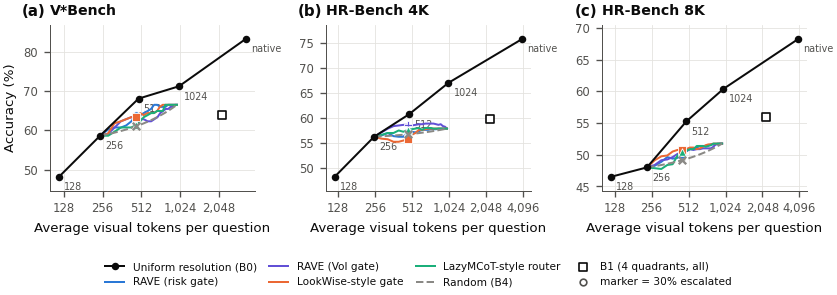

⏱ P6.E1 figure: high-resolution frontiers | wall 2.24 s | CPU 2.12 s (0.94 cores, sys 9.7%) | GPU 0.00 s (no GPU used) | RAM peak 11 GB | A100 time 3.18/7 h
figure -> /content/rave_work/figures/fig14_highres_categories_circular.pdf


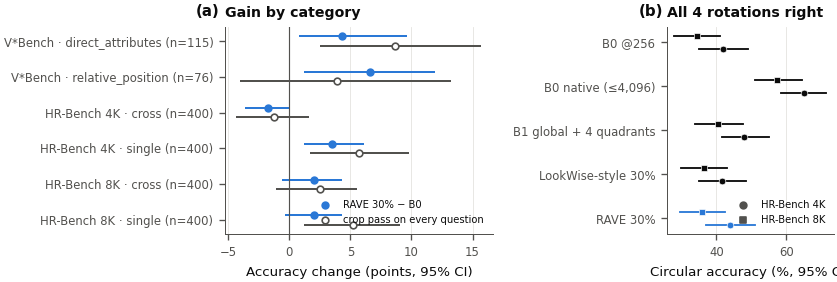

⏱ P6.E2 figure: gains by category + circular accuracy | wall 2.38 s | CPU 8.55 s (3.6 cores, sys 40.6%) | GPU 0.00 s (no GPU used) | RAM peak 11 GB | A100 time 3.18/7 h
figure -> /content/rave_work/figures/fig16_highres_examples.pdf


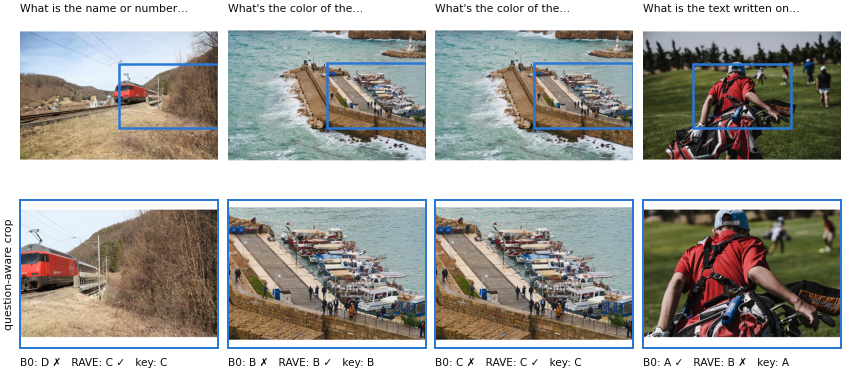

⏱ P6.E4 figure: HR-Bench examples | wall 2.65 s | CPU 2.67 s (1.01 cores, sys 14.2%) | GPU 0.00 s (no GPU used) | RAM peak 11 GB | A100 time 3.18/7 h
figure -> /content/rave_work/figures/fig15_deployment_latency.pdf


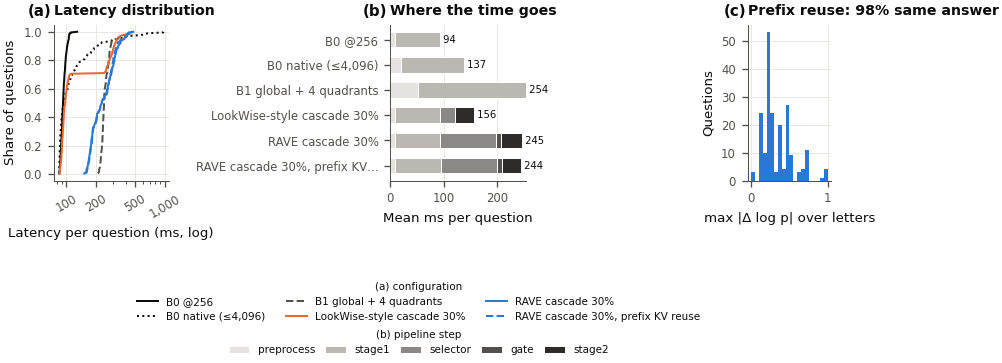

⏱ P6.E3 figure: deployment latency | wall 1.54 s | CPU 1.57 s (1.01 cores, sys 9.8%) | GPU 0.00 s (no GPU used) | RAM peak 11 GB | A100 time 3.18/7 h
⏱ cell 16: if R6: | wall 8.87 s | CPU 14.98 s (1.69 cores, sys 14.5%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.52 kJ, peak 17.55 GB | RAM peak 11 GB | A100 time 3.18/7 h


In [18]:
if R6:
    with Phase("P6.E1 figure: high-resolution frontiers", budget_min=2):
        ks = list(R6)
        fig, axs = plt.subplots(1, len(ks), figsize=(COL2, 2.55), squeeze=False)
        for j, (ax, k) in enumerate(zip(axs[0], ks)):
            plot_frontier(ax, R6[k], SETS[k]["label"])
            panel(ax, "abc"[j])
        axs[0, 0].set_ylabel("Accuracy (%)")
        fig.tight_layout(rect=(0, 0.14, 1, 1), w_pad=1.2)
        frontier_legend(fig, axs[0, 0], ncol=4, y=0.13)
        save_fig(fig, "fig13_highres_frontiers")

    with Phase("P6.E2 figure: gains by category + circular accuracy", budget_min=2):
        rows_ = []
        for k in ks:
            R = R6[k]; EV, E = R["EV"], R["E"]
            g0 = EV.RES[B]["global"]["correct"]; c = EV.policy(B, E)["correct"]; gn = EV.gain(B, "joint_top1", "M1")
            for cat in sorted(R["Q"].category.unique()):
                sel = (R["Q"].category == cat).values
                m_, lo_, hi_ = boot_ci_fast((c - g0)[sel]); mg, lg_, hg = boot_ci_fast(gn[sel])
                rows_.append((f"{SETS[k]['label']} · {cat} (n={int(sel.sum())})", 100 * m_, 100 * lo_, 100 * hi_, 100 * mg, 100 * lg_, 100 * hg))
        hr = [k for k in ks if "cycle_group" in R6[k]["Q"]]
        fig, axs = plt.subplots(1, 2 if hr else 1, figsize=(COL2, 0.24 * len(rows_) + 1.1), squeeze=False,
                                gridspec_kw=dict(width_ratios=[1.6, 1] if hr else [1]))
        ax = axs[0, 0]; ys = np.arange(len(rows_))[::-1]
        for yv, (lab, m_, lo_, hi_, mg, lg_, hg) in zip(ys, rows_):
            ax.plot([lo_, hi_], [yv + 0.13] * 2, color=COLORS["RAVE_risk"], lw=1.2)
            ax.scatter([m_], [yv + 0.13], color=COLORS["RAVE_risk"], s=16, zorder=3, label="RAVE 30% − B0" if yv == ys[0] else None)
            ax.plot([lg_, hg], [yv - 0.13] * 2, color=INK2, lw=1.2)
            ax.scatter([mg], [yv - 0.13], color="white", edgecolor=INK2, s=16, zorder=3, label="crop pass on every question" if yv == ys[0] else None)
        ax.axvline(0, color=INK2, lw=0.7); ax.set_yticks(ys, [r[0] for r in rows_]); ax.grid(axis="y", visible=False)
        ax.set_xlabel("Accuracy change (points, 95% CI)"); ax.set_title("Gain by category"); ax.legend(fontsize=6, loc="lower right")
        panel(ax, "a")
        if hr:
            ax = axs[0, 1]
            meths = list(bench_methods(R6[hr[0]]))
            ys2 = np.arange(len(meths))[::-1]
            for i, (k, mk) in enumerate(zip(hr, ("o", "s"))):
                off = (i - (len(hr) - 1) / 2) * 0.28
                for yv, (lab, c) in zip(ys2, bench_methods(R6[k]).items()):
                    m_, lo_, hi_ = group_metric(c, R6[k]["Q"].cycle_group.values)
                    col = COLORS["RAVE_risk"] if lab.startswith("RAVE") else INK
                    ax.plot([lo_, hi_], [yv + off] * 2, color=col, lw=1.1)
                    ax.scatter([m_], [yv + off], color=col, marker=mk, s=16, zorder=3, edgecolor="white", linewidth=0.4)
                ax.scatter([], [], color=INK2, marker=mk, s=16, label=SETS[k]["label"])
            ax.set_yticks(ys2, meths); ax.grid(axis="y", visible=False)
            ax.set_xlabel("Circular accuracy (%, 95% CI)"); ax.set_title("All 4 rotations right")
            ax.legend(fontsize=6, loc="lower right"); panel(ax, "b")
        fig.tight_layout(w_pad=1.5)
        save_fig(fig, "fig14_highres_categories_circular")

    with Phase("P6.E4 figure: HR-Bench examples", budget_min=2):
        k = "hr8k" if "hr8k" in R6 else ks[-1]
        qualitative("fig16_highres_examples", R6[k], CTX[k], pick_examples(R6[k], 4),
                    text_fn=lambda r: textwrap.shorten(r.question, 40, placeholder="…"))

if LAT is not None:
    with Phase("P6.E3 figure: deployment latency", budget_min=2):
        fig, axs = plt.subplots(1, 3, figsize=(COL2, 3.0), gridspec_kw=dict(width_ratios=[1.1, 1.3, 0.8]))
        style = {f"B0 @{B}": (INK, "-"), "B0 native (≤4,096)": (INK, ":"), "B1 global + 4 quadrants": (INK2, "--"),
                 f"LookWise-style cascade {int(MAIN_RATE * 100)}%": (COLORS["LookWise_conf"], "-"),
                 f"RAVE cascade {int(MAIN_RATE * 100)}%": (COLORS["RAVE_risk"], "-"),
                 f"RAVE cascade {int(MAIN_RATE * 100)}%, prefix KV reuse": (COLORS["RAVE_risk"], "--")}
        ax = axs[0]
        for k_, v in CFG.items():
            x = np.sort(1000 * v.values); col, ls = style[k_]
            ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=col, ls=ls, lw=1.2, label=k_)
        ax.set_xscale("log"); ax.set_xlabel("Latency per question (ms, log)"); ax.set_ylabel("Share of questions")
        from matplotlib.ticker import LogLocator, NullFormatter, FuncFormatter
        ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0), numticks=8))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.tick_params(axis="x", labelrotation=30)
        ax.set_title("Latency distribution"); panel(ax, "a")
        ax = axs[1]
        comps = [c for c in ("preprocess", "stage1", "selector", "gate", "stage2") if c in BRK]
        shades = dict(zip(comps, ["#e4e3df", "#b9b8b3", "#8a8985", "#52514e", "#2d2c2a"]))     # pipeline order, light -> dark
        ys = np.arange(len(BRK))[::-1]; left = np.zeros(len(BRK))
        for c_ in comps:
            ax.barh(ys, BRK[c_].values, left=left, color=shades[c_], height=0.62, label=c_, edgecolor="white", linewidth=0.6)
            left += BRK[c_].values
        for yv, tot in zip(ys, left):
            ax.text(tot, yv, f" {tot:.0f}", va="center", fontsize=6, color=INK)
        ax.set_yticks(ys, [textwrap.shorten(s_, 30, placeholder="…") for s_ in BRK.config]); ax.grid(axis="y", visible=False)
        ax.set_xlabel("Mean ms per question"); ax.set_title("Where the time goes"); ax.margins(x=0.16)
        hb, lb = ax.get_legend_handles_labels()
        panel(ax, "b")
        ax = axs[2]
        if "max_abs_logp" in CHK and CHK.max_abs_logp.notna().any():
            ax.hist(CHK.max_abs_logp.dropna(), bins=20, color=COLORS["RAVE_risk"])
            ax.set_xlabel("max |Δ log p| over letters"); ax.set_ylabel("Questions")
            ax.set_title(f"Prefix reuse: {ok_rate:.0%} same answer")
        else:
            ax.text(0.5, 0.5, "prefix reuse\nnot available", ha="center", va="center", transform=ax.transAxes)
        panel(ax, "c")
        h, l = axs[0].get_legend_handles_labels()
        fig.tight_layout(rect=(0, 0.25, 1, 1), w_pad=1.2)
        fig.legend(h, l, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.2), fontsize=6.2, title="(a) configuration",
                   title_fontsize=6.2)
        fig.legend(hb, lb, loc="upper center", ncol=len(lb), bbox_to_anchor=(0.5, 0.065), fontsize=6.2,
                   title="(b) pipeline step", title_fontsize=6.2, columnspacing=1.0)
        save_fig(fig, "fig15_deployment_latency")

## Summary — results, CPU/GPU time of Portion 6 and of the whole A100 window; save to Drive

In [19]:
summary = dict(benchmarks={k: dict(n=int(R6[k]["EV"].N), tests=R6[k]["tests"], auc=R6[k]["AUC"],
                                   iso=MX6[k]["tradeoff"]["iso"], passes_done=list(DONE6[k]), skipped=SKIP6[k])
                           for k in R6},
               latency=LAT_T.to_dict("records") if LAT is not None else [],
               prefix_cache=dict(used=bool(PREFIX_OK), same_letter=ok_rate) if LAT is not None else {})
(DIRS["logs"] / "results_summary_p6.json").write_text(json.dumps(summary, indent=2, default=float))
window("end of Portion 6")
time_report("P6")
print()
time_report()
sync_to_drive(quiet=False)
save_notebook_copy("RAVE_v4_P6_highres_latency")

⏱ A100 time end of Portion 6: 3.18 h used, 3.82 h left of 7 h (P2–P6 cells)
[P6] 29 cells | wall 80.7 min | CPU 164.1 CPU-min (2.0 cores avg) | GPU busy 52.08 min (phases) / 50.66 min (cells, NVML) | GPU energy 1293.6 kJ | A100 time used (P2–P6) 3.18 h of 7

[all notebooks] 116 cells | wall 220.0 min | CPU 461.3 CPU-min (2.1 cores avg) | GPU busy 161.98 min (phases) / 151.37 min (cells, NVML) | GPU energy 3790.5 kJ | A100 time used (P2–P6) 3.18 h of 7
Drive sync: 0 file(s) -> /content/drive/MyDrive/Koushik 2/rave_work
notebook with outputs -> /content/drive/MyDrive/Koushik 2/notebooks/RAVE_v4_P6_highres_latency_executed_20261020_1854.ipynb
⏱ cell 17: summary = dict(benchmarks={k: dict(n=int(R6[k]["EV"].N), tes | wall 2.33 s | CPU 0.13 s (0.05 cores, sys 1.7%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.12 kJ, peak 17.55 GB | RAM peak 11 GB | A100 time 3.19/7 h
